<div style="border-left:4px solid #3D6FB0;padding:6px 0 8px 16px;"><div style="opacity:.72;font-size:12px;letter-spacing:1.4px;">Minería de Datos · Proyecto Final</div><div style="color:#3D6FB0;font-size:27px;font-weight:700;margin-top:4px;">Análisis Exploratorio del Spanish Fake News Corpus</div><div style="opacity:.72;font-size:14px;margin-top:6px;margin-bottom:10px;">Miguel A. Garcia, Nadia Ramos, Ángel J. Zamora</div><img src="https://mmss.iimas.unam.mx/dmmss/wp-content/uploads/2026/02/cropped-LogoUNAM_IIMAS_Negro50-scaled-2.png" width="200"/></div>

Proyecto basado en *FakeDeS: Fake News Detection in Spanish Shared Task at IberLEF 2021*, organizada en colaboración con MexLef.

Este notebook cubre las dos primeras fases de CRISP-DM: comprensión del negocio y comprensión de los datos. **Solo lee** los archivos de `data/` y no los modifica; las transformaciones (renombrar columnas, unificar etiquetas) se hacen en memoria. Las figuras se guardan en `figuras/` y las tablas en `resultados/eda_*.csv`.

## Contenido

    * [Sección 0: Configuración](#seccion-0)
* **[Metodología CRISP-DM: Comprensión del negocio](#fase-negocio)**
    * [Sección 1: Comprensión del negocio](#seccion-1)
    * [Sección 2: Estado del arte](#seccion-2)
* **[Metodología CRISP-DM: Comprensión de los datos](#fase-datos)**
    * [Sección 3: Recolección inicial de los datos](#seccion-3)
    * [Sección 4: Homogeneización entre versiones](#seccion-4)
    * [Sección 5: Calidad de los datos](#seccion-5)
    * [Sección 6: Distribución de clases](#seccion-6)
    * [Sección 7: Temas](#seccion-7)
    * [Sección 8: Fuentes](#seccion-8)
    * [Sección 9: Longitud de los textos](#seccion-9)
    * [Sección 10: Rasgos de estilo](#seccion-10)
    * [Sección 11: Vocabulario](#seccion-11)
    * [Sección 12: Casi duplicados y pares de un mismo hecho](#seccion-12)
    * [Sección 13: Atípicos del texto](#seccion-13)
    * [Sección 14: El medio dentro del texto](#seccion-14)
    * [Sección 15: Comparación entre versiones](#seccion-15)
    * [Sección 16: Reporte de calidad por dimensiones](#seccion-16)
* **[Conclusiones](#conclusiones)**
    * [Sección 17: Resumen por sección](#seccion-17)
    * [Sección 18: Implicaciones para la preparación de los datos](#seccion-18)
    * [Sección 19: Referencias](#seccion-19)

<a id="seccion-0"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 0: Configuración</span></div>

> **Qué se hace:** cargamos las bibliotecas, fijamos las constantes (semilla, colores, rutas) y verificamos el entorno.
>
> **Qué se espera ver:** el entorno `fakedes` con las versiones que se registran en la Tabla 0.4.

### 0.1 Bibliotecas

Las funciones que comparten todos los notebooks (carga, métrica, `guardar`) están en `utils_fakedes.py`.

In [1]:
# Manejo de datos
import os
import re
import sys
import unicodedata
from collections import Counter
import numpy as np
import pandas as pd

# Visualización
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

# Estadística y similitud de textos
import scipy
import sklearn
import ftfy
from scipy import stats
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from rapidfuzz import fuzz

# Palabras vacías
import stopwordsiso as sw

# Funciones compartidas del proyecto
import utils_fakedes as uf
from utils_fakedes import guardar, guardar_csv, f1_fake, metricas

### 0.2 Constantes

La semilla se define una sola vez en `utils_fakedes.py` y aquí solo se lee.

In [2]:
SEMILLA = uf.SEMILLA                      # 42
COLORES_CLASE = uf.COLORES_CLASE          # {'True': 'C0', 'Fake': 'red'}
COLORES_PARTICION = uf.COLORES_PARTICION
TINTA, TINTA_SUAVE = uf.TINTA, uf.TINTA_SUAVE
RUTA_DATOS, ARCHIVOS = uf.RUTA_DATOS, uf.ARCHIVOS

STOPWORDS_ES = sw.stopwords('es')
STOPWORDS_EN = sw.stopwords('en')
UMBRAL_CASI_DUPLICADO = 0.8               # coseno TF-IDF a partir del cual dos textos se revisan como casi duplicados
UMBRAL_PAR = 0.3                          # coseno entre titulares para aceptar un par verdadera–falsa candidato

uf.configurar_graficas()
pd.set_option('display.max_colwidth', 80)

### 0.3 Rutas y carpetas de salida

**Tabla 0.3.** Carpetas que usa el notebook.

In [3]:
uf.crear_carpetas(uf.RUTA_FIGURAS, uf.RUTA_RESULTADOS)
pd.DataFrame({'carpeta': [RUTA_DATOS, uf.RUTA_FIGURAS, uf.RUTA_RESULTADOS],
              'uso': ['lectura de los .xlsx originales (no se modifican)', 'figuras PNG (guardar)', 'tablas CSV (eda_*)']})

,carpeta,uso
0,data,lectura de los .xlsx originales (no se modifican)
1,figuras,figuras PNG (guardar)
2,resultados,tablas CSV (eda_*)


### 0.4 Verificación del entorno (Tabla 0.4)

**Tabla 0.4.** Intérprete y versiones de las bibliotecas principales.

In [4]:
pd.Series({'intérprete': sys.executable, 'Python': sys.version.split()[0], 'pandas': pd.__version__,
           'numpy': np.__version__, 'scikit-learn': sklearn.__version__, 'scipy': scipy.__version__,
           'matplotlib': matplotlib.__version__, 'seaborn': sns.__version__}, name = 'valor').to_frame()

,valor
intérprete,C:\Users\Equipo\miniconda3\envs\fakedes\python.exe
Python,3.11.18
pandas,3.1.1
numpy,2.4.6
scikit-learn,1.9.1
scipy,1.17.1
matplotlib,3.11.2
seaborn,0.13.2


<a id="fase-negocio"></a>

# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Metodología CRISP-DM: Comprensión del negocio</span></div>

<a id="seccion-1"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 1: Comprensión del negocio</span></div>

> **Qué se hace:** seguimos las cuatro tareas de CRISP-DM para esta fase: objetivos del negocio, evaluación de la situación, objetivos de minería de datos y plan del proyecto.
>
> **Qué se espera ver:** un objetivo medible (F1 de la clase *fake* en un dominio nuevo), la meta numérica tomada de los baselines oficiales y los riesgos que condicionan el resto del proyecto.

#### Glosario de la sección
* **F1 de la clase fake:** media armónica de la precisión y la exhaustividad calculadas tratando *fake* como clase positiva; es la métrica oficial de FakeDeS 2021.
* **Baseline:** sistema de referencia sencillo; un modelo que no lo supera no aporta.
* **Atajo (shortcut):** regla que el modelo aprende y que predice bien en los datos de entrenamiento sin relación causal con la clase (por ejemplo, el estilo de un medio).
* **Cambio de dominio:** diferencia entre los datos de entrenamiento y los de uso (otro periodo, otros temas, otras fuentes).
* **Validación cruzada agrupada:** partición en *folds* donde todas las noticias de un mismo grupo (aquí, la fuente) quedan en el mismo fold.

### 1.1 Antecedentes

La desinformación es la difusión intencionada de información falsa o engañosa para influir en la opinión pública o causar daño; a diferencia de la información falsa sin intención (*misinformation*), implica manipulación [7]. Las redes sociales aceleran su difusión, y verificarla a mano es lento y caro: los sitios de verificación (*fact-checkers*) solo alcanzan a revisar una fracción de lo que circula.

FakeDeS 2021 [1] propone detectar noticias falsas en español a partir de su texto. Se entrena con noticias mexicanas de 2018 (versión 1.0 del corpus) y se evalúa con noticias de noviembre de 2020 a marzo de 2021 (versión 2.0) que traen **dos desafíos explícitos: variación temática** (COVID-19 no existe en el entrenamiento) **y variación lingüística** (noticias de 13 países además de México). Participaron 21 equipos; ninguno verificó hechos contra fuentes externas: todos clasificaron por rasgos de estilo y contenido [1].

**Quién usaría el sistema:** un equipo de verificación o una plataforma que quiere **priorizar** qué contenido revisar primero. El sistema no decide qué es verdad: ordena la cola de revisión humana.

### 1.2 Objetivos del negocio y criterio de éxito

| Objetivo del negocio | Criterio de éxito del negocio |
|:--|:--|
| Señalar noticias potencialmente falsas en español para filtrarlas o priorizarlas para verificación humana. | Que el sistema detecte noticias falsas de un periodo, temas y fuentes que no vio al entrenar mejor que los baselines oficiales de la tarea (Tabla 1.4). |
| Entender en qué se basa la decisión. | Poder explicar con rasgos interpretables (palabras, estilo) por qué una noticia se marca como falsa, y documentar los atajos detectados. |
| Mostrar el sistema funcionando. | Una demostración en línea (API) que reciba titular y texto y devuelva la clase, según la propuesta del proyecto [8]. |

### 1.3 Evaluación de la situación

**Inventario de recursos**

| Recurso | Disponible |
|:--|:--|
| Personal | Tres estudiantes de la LCD (Miguel A. García, Nadia Ramos, Ángel J. Zamora); asesoría de la profesora Ileana Grave. |
| Datos | *The Spanish Fake News Corpus* [3], versiones 1.0 y 2.0: 1,543 noticias en tres archivos `.xlsx`, público con licencia CC BY 4.0. |
| Hardware | Computadoras personales sin GPU. Un transformer (BETO) requeriría Google Colab. |
| Software | Python 3.11 en el entorno conda `fakedes` (Tabla 0.4); scikit-learn, pandas, scipy, xgboost, lime. |

**Requisitos, supuestos y restricciones**

| Tipo | Descripción |
|:--|:--|
| Requisito | Entrega final el 3 de diciembre de 2026; repositorio reproducible (semilla fija, entorno exportado). |
| Requisito legal | Atribuir el corpus (CC BY 4.0) a sus autores; no redistribuir textos fuera del repositorio. |
| Supuesto | Las etiquetas son correctas: se asignaron a mano con evidencia de sitios confiables o verificadores [1, 3]. No es verificable con los datos; no hay acuerdo entre anotadores publicado. |
| Supuesto | El criterio de "falso" es el mismo en ambas versiones. Es parcialmente falso: la 2.0 incluye 90 publicaciones de redes sociales como falsas y la 1.0 no tiene ninguna (Sección 13). |
| Restricción | Corpus pequeño (971 noticias para entrenar), lo que favorece modelos lineales y validación cuidadosa. |
| Restricción | Solo `Headline` y `Text` se usan como entrada; `Source`, `Link`, `Id` y `Topic` solo sirven para analizar y agrupar (Sección 8). |
| Restricción | No se usan APIs externas. |

**Riesgos y contingencias**

| Riesgo | Efecto | Contingencia |
|:--|:--|:--|
| Atajo por medio: la fuente casi determina la clase (Sección 8). | El modelo aprende el estilo del medio y falla con medios nuevos. | Validación cruzada agrupada por fuente; enmascarar el nombre del medio en el texto (Sección 14). |
| Cambio de dominio entre versiones. | Puntajes de validación optimistas; en FakeDeS, un BERT pasó de .7655 en `development` a .4719 en test [9]. | No usar `development` como única validación; medir el test una sola vez. |
| Fuga por duplicados entre particiones. | Puntajes inflados. | Deduplicar exactos y casi exactos antes de partir (Secciones 5 y 12). |
| Falta de tiempo (cuatro semanas). | No llegar al transformer ni a la demo. | Priorizar modelos clásicos; el transformer queda planeado. |

**Costos y beneficios.** Un falso negativo deja circular una noticia falsa; un falso positivo consume tiempo de un verificador en una noticia verdadera. Ninguno de los dos domina en el planteamiento de la tarea, por eso la F1 de *fake* (que combina precisión y exhaustividad) es una métrica adecuada. El costo computacional de los modelos clásicos es de segundos en CPU.

### 1.4 Objetivos de minería de datos y criterio de éxito técnico

**Objetivo de minería:** construir un clasificador binario que, a partir del titular y el texto de una noticia, prediga `True` o `Fake`, entrenado con la versión 1.0 y evaluado una sola vez con la versión 2.0.

**Métrica principal:** F1 de la clase `Fake` sobre `test`, igual que el ranking oficial [1], con intervalo de confianza por bootstrap porque el test tiene solo 572 noticias. **Complementarias:** F1 de `True`, macro-F1, exactitud, precisión y exhaustividad de `Fake` y matriz de confusión, como indica la propuesta [8].

⚠️ La conclusión del EDA anterior mencionaba "F1 macro"; la unificamos con la propuesta y con la tarea oficial: **F1 de fake es la principal** y la macro-F1 es complementaria. En la tabla 4 del overview la columna `Fmacro` es idéntica a la de `Fake` para los 24 sistemas, así que no comparamos macro-F1 con esa tabla.

**Tabla 1.4.** Resultados oficiales en `test` que sirven de meta [1]. Son comparables con los nuestros: misma partición y misma métrica.

| Referencia | F1 fake | F1 true | Exactitud |
|:--|--:|--:|--:|
| Baseline 3-gramas de caracteres + SVM | .7063 | .6883 | .6976 |
| Baseline BoW + SVM | .7217 | .7359 | .7290 |
| Baseline BETO | .7321 | .7432 | .7378 |
| 2.º lugar (HAHA, usa fuente y tema) | .7548 | .7522 | .7535 |
| 1.er lugar (GDUFS_DM) | .7666 | .7649 | .7657 |

**Criterio de éxito técnico:** superar el baseline BoW + SVM (.7217) con un modelo clásico que use solo titular y texto; acercarse a BETO (.7321) sería un buen resultado. Una diferencia que quede dentro del intervalo de confianza no cuenta como mejora.

### 1.5 Métrica oficial: implementación y ejemplo de juguete

Con *fake* como clase positiva:

$$P_{fake} = \frac{TP}{TP + FP}, \qquad R_{fake} = \frac{TP}{TP + FN}, \qquad F1_{fake} = \frac{2\,P_{fake}\,R_{fake}}{P_{fake} + R_{fake}} = \frac{2\,TP}{2\,TP + FP + FN}$$

* $TP$: noticias falsas predichas como falsas.
* $FP$: noticias verdaderas predichas como falsas.
* $FN$: noticias falsas predichas como verdaderas.
* La macro-F1 es el promedio simple de $F1_{fake}$ y $F1_{true}$.

Probamos `f1_fake` (en `utils_fakedes.py`) con un ejemplo inventado de 8 noticias calculado a mano: $TP = 3$, $FP = 2$, $FN = 1$, $TN = 2$, así que $F1_{fake} = 6 / (6 + 2 + 1) = 0.667$, $F1_{true} = 4 / (4 + 1 + 2) = 0.571$, macro-F1 $= 0.619$ y exactitud $= 5/8 = 0.625$. También probamos dos casos límite: predecir todo como verdadero ($F1_{fake} = 0$, sin error por división entre cero) y una predicción perfecta.

**Tabla 1.5.** Valor esperado (a mano) frente a obtenido.

In [5]:
y_real = ['Fake', 'Fake', 'Fake', 'True', 'True', 'True', 'True', 'Fake']
y_pred = ['Fake', 'True', 'Fake', 'Fake', 'True', 'Fake', 'True', 'Fake']
obtenido = metricas(y_real, y_pred)

pruebas = pd.DataFrame([
    ('F1 fake', 6 / 9, obtenido['F1_fake']), ('F1 true', 4 / 7, obtenido['F1_true']),
    ('macro-F1', (6 / 9 + 4 / 7) / 2, obtenido['F1_macro']), ('exactitud', 5 / 8, obtenido['accuracy']),
    ('F1 fake, todo predicho True', 0.0, f1_fake(y_real, ['True'] * 8)),
    ('F1 fake, predicción perfecta', 1.0, f1_fake(y_real, y_real))], columns = ['prueba', 'esperado', 'obtenido'])
pruebas['resultado'] = np.where(np.isclose(pruebas['esperado'], pruebas['obtenido']), '✅', '❌')
pruebas.round(3)

,prueba,esperado,obtenido,resultado
0,F1 fake,0.667,0.667,✅
1,F1 true,0.571,0.571,✅
2,macro-F1,0.619,0.619,✅
3,exactitud,0.625,0.625,✅
4,"F1 fake, todo predicho True",0.000,0.000,✅
5,"F1 fake, predicción perfecta",1.000,1.000,✅


**Qué se observa.** Las 6 pruebas pasan (6 de 6 ✅): `f1_fake` y `metricas` reproducen los valores calculados a mano, y predecir todo como verdadero da F1 de fake = 0 sin error. **Usamos estas dos funciones en todos los notebooks para que la métrica sea la misma en validación y en test.**

**Ambigüedades de la métrica** y cómo las resolvemos:

* **Clase positiva:** `Fake`. En `test.xlsx` la clase es booleana y `True` significa noticia verdadera; la homogeneización (Sección 4) la convierte a `True` / `Fake`.
* **Sin verdaderos positivos:** la F1 se define como 0 (`zero_division = 0`), como en el caso límite de la Tabla 1.5.
* **Macro-F1:** la calculamos nosotros; la columna `Fmacro` del overview no es una macro-F1 (ver 1.4).

### 1.6 Plan del proyecto

**Tabla 1.6.** Plan de trabajo de la propuesta [8], con los notebooks que produce cada fase. Solo `evaluacion.ipynb` carga el test.

| Semana | Fechas | Fase de CRISP-DM | Notebook | Producto |
|:--|:--|:--|:--|:--|
| 1 | 5 al 10 de noviembre | Comprensión del negocio y de los datos | `analisis_exploratorio.ipynb` | Objetivos y EDA (este notebook) |
| 2 | 11 al 17 de noviembre | Preparación de los datos | `preparacion_datos.ipynb` | `data/processed/corpus.parquet`, `resultados/folds.csv` |
| 3 | 18 al 24 de noviembre | Modelado | `modelos_lineales.ipynb`, `modelo_arboles.ipynb` | Resultados de validación cruzada |
| 4 | 25 de noviembre al 1 de diciembre | Evaluación y despliegue | `evaluacion.ipynb` | Evaluación única en test, API de demostración |
| Cierre | 2 y 3 de diciembre | Revisión | — | Reproducibilidad y reporte final |

**Evaluación inicial de herramientas:** scikit-learn cubre TF-IDF, modelos lineales, `StratifiedGroupKFold` y `Pipeline`, que garantiza que vocabulario e IDF se ajusten solo con el train de cada fold. Un transformer en español (BETO) requiere GPU; queda planeado para Colab.

<a id="seccion-2"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 2: Estado del arte</span></div>

> **Qué se hace:** resumimos el overview oficial de FakeDeS 2021 [1] y los artículos de los equipos publicados en CEUR-WS Vol. 2943 [9–11]; la tabla completa y las referencias están en `notas/estado_del_arte.md`.
>
> **Qué se espera ver:** que los métodos clásicos sean competitivos, que los puntajes de `development` no anticipen los de test y qué ideas conviene probar.

### 2.1 Qué hicieron los mejores sistemas (Tabla 2.1)

**Tabla 2.1.** Sistemas con artículo publicado. F1 de fake en `test`, tomada de la tabla 4 del overview [1].

| Sistema | Lugar | Representación y modelo | Trucos | F1 fake | ¿Usa información que no tendremos? |
|:--|:--|:--|:--|--:|:--|
| GDUFS_DM [9] | 1 | BETO cased con los primeros y los últimos 512 tokens + "memoria de muestras" con atención | Cabeza + cola, *early stopping* | .7666 | Sí: inicializa la memoria con muestras de test |
| HAHA [10] | 2 | TF-IDF + *stacking* de 5 lineales con LightGBM | Fuente y tema codificados como variables | .7548 | Sí: fuente, dominio y tema |
| LCAD-UFES | 5 | Secuencias de POS y entidades + *gradient boosting* | — | .7102 | No |
| CiTIUS [11] | 6 | Similitud de oraciones con BERT + heurísticas (longitud, mayúsculas) | — | .7098 | No |
| ForceNLP | 8 | n-gramas de caracteres, palabras, POS y puntuación + regresión logística | — | .6925 | No |

### 2.2 Lo que se repite

* **`development` es optimista.** CiTIUS: su BERT bajó de .7655 en `development` a .4719 en test [11]. HAHA reporta cerca de .90 en `development` y .7548 en test [10]. Por eso no usaremos `development` como única validación.
* **Los metadatos inflan.** HAHA obtuvo .7548 con fuente y tema contra .6975 sin ellos (en esa comparación también cambió el manejo de stopwords) [10].
* **Los clásicos compiten.** El segundo lugar es un modelo TF-IDF; la diferencia entre el baseline BoW + SVM y el ganador es de .045 [1].
* **Los enfoques se complementan.** La exactitud máxima posible combinando los 21 equipos es .9965; con solo transformers, .9528, y con solo métodos clásicos, .9580 [1].
* **COVID-19 no fue más difícil.** El promedio de F1 de fake por tema fue .66 en COVID-19 contra .68 en Política y Sociedad [1].

### 2.3 Ideas que probaremos (hipótesis, no recetas)

| Idea | Origen | Dónde se prueba |
|:--|:--|:--|
| TF-IDF de caracteres y de palabras en bloques separados | Baselines oficiales, ForceNLP | `modelos_lineales.ipynb` |
| Conservar stopwords y puntuación | HAHA (quitarlas bajó su desempeño) | `modelos_lineales.ipynb` |
| Titular y texto en bloques separados frente a concatenados | GDUFS_DM concatena | `modelos_lineales.ipynb` |
| Rasgos de estilo (longitud, mayúsculas, signos) | CiTIUS; Sección 10 de este notebook | `modelo_arboles.ipynb` |
| Truncado cabeza + cola para BETO | GDUFS_DM | Solo planeado |

<a id="fase-datos"></a>

# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Metodología CRISP-DM: Comprensión de los datos</span></div>

<a id="seccion-3"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 3: Recolección inicial de los datos</span></div>

> **Qué se hace:** leemos los tres archivos, describimos su origen y armamos el diccionario de datos con el rol de cada columna.
>
> **Qué se espera ver:** tres archivos de dos versiones del corpus con formatos distintos, ninguno de ellos un archivo de predicciones.

### 3.1 Origen de los archivos (Tabla 3.1)

**Tabla 3.1.** Archivos del repositorio y versión del corpus a la que pertenecen.

| Archivo | Versión | Periodo de recolección | Uso original |
|:--|:--|:--|:--|
| `train.xlsx` | 1.0 | Enero a julio de 2018 | Entrenamiento (MEX-A3T 2020) |
| `development.xlsx` | 1.0 | Enero a julio de 2018 | Prueba de MEX-A3T 2020; desarrollo en FakeDeS 2021 |
| `test.xlsx` | 2.0 | Noviembre de 2020 a marzo de 2021 | Prueba (FakeDeS 2021) |

Según el README, la versión 1.0 se dividió en 70 % para entrenamiento y 30 % para prueba de forma estratificada por tema, y ambas versiones se armaron por pares de noticia falsa y verdadera sobre un mismo hecho.

### 3.2 Lectura de los archivos

Leemos los archivos sin modificarlos. **Tabla 3.2.** Tamaño de cada archivo.

In [6]:
def cargar_archivo(archivo):
    '''
    Función que lee un archivo del corpus desde la carpeta local

    inputs:
    --------
        archivo (str): Nombre del archivo .xlsx

    outputs:
    --------
        pandas.DataFrame: Contenido del archivo sin modificar
    '''
    return pd.read_excel(os.path.join(RUTA_DATOS, archivo))

crudos = {particion: cargar_archivo(archivo) for particion, archivo in ARCHIVOS.items()}
pd.DataFrame({p: {'filas': df.shape[0], 'columnas': df.shape[1]} for p, df in crudos.items()}).T

,filas,columnas
train,676,7
development,295,7
test,572,7


**Tabla 3.3.** Nombres y tipos de las columnas en cada archivo.

In [7]:
pd.DataFrame({p: [f'{c} ({t})' for c, t in df.dtypes.astype(str).items()] for p, df in crudos.items()},
             index = [f'columna {i + 1}' for i in range(7)])

,train,development,test
columna 1,Id (int64),Id (int64),ID (int64)
columna 2,Category (str),Category (str),CATEGORY (bool)
columna 3,Topic (str),Topic (str),TOPICS (str)
columna 4,Source (str),Source (str),SOURCE (str)
columna 5,Headline (str),Headline (str),HEADLINE (str)
columna 6,Text (str),Text (str),TEXT (str)
columna 7,Link (str),Link (str),LINK (str)


**Qué se observa.** Los tres archivos tienen 7 columnas en el mismo orden, pero `test.xlsx` las nombra en mayúsculas, llama `TOPICS` al tema y guarda la clase como booleano (`bool`) en lugar de texto. **Antes de unir los archivos hay que mapear el esquema de la 2.0 al de la 1.0 (Sección 4).**

### 3.4 Diccionario de datos y rol de cada columna (Tabla 3.4)

**Unidad de análisis:** una noticia (titular + texto) con su etiqueta. **Tipo de dato:** `Headline` y `Text` son texto no estructurado; las demás columnas son estructuradas.

**Tabla 3.4.** Diccionario de datos. El dominio válido se verifica en la Sección 5.6.

| Variable | Definición | Tipo | Dominio válido | Codificación 1.0 → 2.0 | Rol |
|:--|:--|:--|:--|:--|:--|
| `Id` | Identificador de la instancia | entero | entero positivo, único dentro del archivo | `Id` → `ID` | identificador |
| `Category` | Clase de la noticia | categórica | `True`, `Fake` | texto → booleano (`True` = verdadera) | **etiqueta** |
| `Topic` | Tema asignado por la fuente | categórica | 9 temas (1.0) / 7 temas (2.0) | inglés → español (`TOPICS`) | análisis y agrupamiento |
| `Source` | Nombre del medio o sitio | texto corto | cualquier nombre; en la 2.0 puede faltar | `Source` → `SOURCE` | **grupo** de los folds; no es entrada |
| `Headline` | Titular | texto | no vacío; en la 2.0 puede faltar a propósito | `Headline` → `HEADLINE` | **texto (entrada)** |
| `Text` | Texto completo | texto | no vacío, con letras | `Text` → `TEXT`; la 1.0 viene anonimizada | **texto principal (entrada)** |
| `Link` | URL de la noticia | texto | `http(s)://…`; en la 2.0 puede faltar | `Link` → `LINK` | metadato; no es entrada |

El README aclara que **algunos titulares faltan a propósito** porque la fuente no los tenía; no es un error de captura.

### 3.5 Verificación de que ningún archivo es de predicciones

Un archivo de ejemplo de envío (*sample submission*) tendría una sola clase o no tendría texto. **Tabla 3.5.** Comprobaciones por archivo.

In [8]:
verificacion = pd.DataFrame({p: {'7 columnas': df.shape[1] == 7,
                                 'dos clases': df.iloc[:, 1].nunique() == 2,
                                 'texto no vacío': df.iloc[:, 5].notna().all()} for p, df in crudos.items()}).T
verificacion.replace({True: '✅', False: '❌'})

,7 columnas,dos clases,texto no vacío
train,✅,✅,✅
development,✅,✅,✅
test,✅,✅,✅


**Qué se observa.** Los tres archivos pasan las 3 comprobaciones (9 de 9 ✅): todos tienen texto y las dos clases, incluido `test.xlsx`, que trae sus etiquetas. La propuesta decía que el conjunto de evaluación solo traía identificador, titular y texto; el archivo publicado sí trae la clase. **Por eso la regla de no usar el test para decidir la garantiza la estructura del proyecto: solo `evaluacion.ipynb` lo carga.**

<a id="seccion-4"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 4: Homogeneización entre versiones</span></div>

> **Qué se hace:** llevamos `test.xlsx` (versión 2.0) al esquema de la versión 1.0: nombres de columnas, clase y temas.
>
> **Qué se espera ver:** un solo `corpus` de 1,543 filas con las columnas `particion` y `version`.

⚠️ La homogeneización se hace en memoria; los archivos originales no se modifican.

Los archivos no comparten formato: en `test.xlsx` las columnas están en mayúsculas (el tema se llama `TOPICS`), la clase es booleana y los temas están en español. Renombramos las columnas, convertimos la clase a `True` / `Fake` y traducimos los temas al inglés con los nombres del README.

**Tabla 4.1.** Noticias por clase y partición después de unir.

In [9]:
temas_es = uf.TEMAS_ES
test = crudos['test'].copy()
test.columns = crudos['train'].columns
test['Category'] = test['Category'].map({True: 'True', False: 'Fake'})
test['Topic'] = test['Topic'].map(temas_es)

corpus = pd.concat([crudos['train'].assign(particion = 'train'),
                    crudos['development'].assign(particion = 'development'),
                    test.assign(particion = 'test')], ignore_index = True)
corpus['version'] = np.where(corpus['particion'] == 'test', '2.0', '1.0')
corpus = corpus.astype({c: 'object' for c in ['Category', 'Topic', 'Source', 'Headline', 'Text', 'Link']})
particiones = list(ARCHIVOS)
corpus.groupby('particion', sort = False)['Category'].value_counts().unstack()

Category,Fake,True
particion,,
train,338,338
development,142,153
test,286,286


**Qué se observa.** El corpus unificado tiene 1,543 noticias: 676 en `train` (338 / 338), 295 en `development` (142 falsas, 153 verdaderas) y 572 en `test` (286 / 286). Los totales de la versión 1.0, 491 verdaderas y 480 falsas, coinciden con el README y con la tabla 1 del overview. **La homogeneización no perdió ni duplicó filas.**

`utils_fakedes.cargar_corpus()` repite exactamente estos pasos para los demás notebooks. **Tabla 4.2.** Comprobación de que ambas rutas producen el mismo corpus.

In [10]:
pd.DataFrame({'comprobación': ['cargar_corpus() == corpus'],
              'resultado': ['✅' if uf.cargar_corpus().equals(corpus) else '❌']})

,comprobación,resultado
0,cargar_corpus() == corpus,✅


<a id="seccion-5"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 5: Calidad de los datos</span></div>

> **Qué se hace:** medimos nulos, duplicados exactos, variantes de escritura, marcas de anonimización y reglas de validez.
>
> **Qué se espera ver:** pocos problemas en la versión 1.0, titulares faltantes concentrados en una clase en la 2.0 y algunas repeticiones entre `train` y `development`.

⚠️ Esta sección solo detecta y mide; no corrige nada. Las correcciones se hacen en `preparacion_datos.ipynb`.

### 5.1 Valores nulos (Tabla 5.1)

**Tabla 5.1.** Registros con valores nulos por columna y partición.

In [11]:
nulos = corpus.drop(columns = ['particion', 'version']).isnull().groupby(corpus['particion'], sort = False).sum()
nulos

,Id,Category,Topic,Source,Headline,Text,Link
particion,,,,,,,
train,0,0,0,0,0,0,0
development,0,0,0,0,0,0,0
test,0,0,0,7,72,0,3


### 5.2 Mecanismo del faltante (Tabla 5.2)

Cruzamos los faltantes con la clase: si se concentran en una clase, no son faltantes al azar (no MCAR) y eliminar esas filas sesgaría el corpus.

**Tabla 5.2.** Faltantes de `test` por clase.

In [12]:
nulos_test = corpus[corpus['particion'] == 'test']
faltantes_clase = pd.DataFrame({'sin Headline': nulos_test['Headline'].isnull().groupby(nulos_test['Category']).sum(),
                                'sin Source': nulos_test['Source'].isnull().groupby(nulos_test['Category']).sum(),
                                'sin Link': nulos_test['Link'].isnull().groupby(nulos_test['Category']).sum()})
faltantes_clase

,sin Headline,sin Source,sin Link
Category,,,
Fake,72,5,3
True,0,2,0


**Tabla 5.3.** Fuentes de las noticias sin titular.

In [13]:
nulos_test.loc[nulos_test['Headline'].isnull(), 'Source'].value_counts().rename('noticias sin titular').to_frame()

,noticias sin titular
Source,
AFPFactual,58
Agencia EFE,7
Colombia Check,1
Facebook,1
Maldita,1


**Qué se observa.** Solo `test.xlsx` tiene valores nulos, y **los 72 registros sin titular son noticias falsas**; la mayoría son publicaciones de redes sociales verificadas por AFP Factual (el README aclara que algunas fuentes omiten el titular). El faltante depende de la clase: no es MCAR. **Un modelo que reciba un titular vacío aprendería que eso indica una noticia falsa; en la preparación el titular vacío se rellena con una cadena neutra y su ausencia no se usa como variable.**

### 5.3 Duplicados exactos y fuga entre particiones (Tabla 5.4)

**Tabla 5.4.** Repeticiones dentro de cada partición y entre particiones.

In [14]:
train, dev = corpus[corpus['particion'] == 'train'], corpus[corpus['particion'] == 'development']
duplicados = pd.DataFrame({p: {'IDs duplicados': df['Id'].duplicated().sum(), 'textos duplicados': df['Text'].duplicated().sum(),
                               'links duplicados': df['Link'].dropna().duplicated().sum()}
                           for p in particiones for df in [corpus[corpus['particion'] == p]]}).T
duplicados['textos presentes en train'] = [np.nan, dev['Text'].isin(train['Text']).sum(), test['Text'].isin(train['Text']).sum()]
duplicados['IDs presentes en train'] = [np.nan, dev['Id'].isin(train['Id']).sum(), test['Id'].isin(train['Id']).sum()]
duplicados

,IDs duplicados,textos duplicados,links duplicados,textos presentes en train,IDs presentes en train
train,0,0,0,NaN,NaN
development,0,1,1,4.0,295.0
test,0,0,0,0.0,572.0


Un duplicado con etiquetas distintas sería ruido de anotación. **Tabla 5.5.** Número de clases distintas entre las copias de cada texto repetido de la versión 1.0.

In [15]:
v1 = corpus[corpus['version'] == '1.0']
repetidos = v1[v1['Text'].duplicated(keep = False)]
repetidos.groupby('Text')['Category'].nunique().value_counts().rename('textos repetidos').rename_axis('clases distintas').to_frame()

,textos repetidos
clases distintas,
1,5


**Qué se observa.** Los 5 textos repetidos de la versión 1.0 (4 entre `train` y `development` y 1 dentro de `development`) conservan la misma clase en todas sus copias. **No hay contradicciones de etiqueta entre duplicados exactos; el problema es de unicidad (fuga entre particiones), no de exactitud.**

### 5.4 Variantes de escritura en los nombres de las fuentes (Tabla 5.6)

**Tabla 5.6.** Fuentes distintas antes y después de normalizar mayúsculas y espacios.

In [16]:
pd.DataFrame({p: {'fuentes distintas': f.nunique(), 'al normalizar': f.str.strip().str.lower().nunique()}
              for p in particiones for f in [corpus.loc[corpus['particion'] == p, 'Source'].dropna()]}).T

,fuentes distintas,al normalizar
train,134,122
development,82,72
test,205,199


**Tabla 5.7.** Ejemplos de una misma fuente escrita de varias formas.

In [17]:
variantes = corpus.groupby(corpus['Source'].str.strip().str.lower())['Source'].unique()
variantes[variantes.str.len() > 1].head(8).rename('variantes').to_frame()

,variantes
Source,
abc,"[ABC, abc]"
alerta digital,"[Alerta digital, Alerta Digital]"
animal político,"[Animal Político, Animal político]"
argumento político,"[Argumento Político, ARGUMENTO POLÍTICO]"
aristegui noticias,"[Aristegui noticias, Aristegui Noticias]"
as,"[as, AS]"
cnn español,"[CNN español, CNN Español]"
el comercio,"[El Comercio, El comercio]"


### 5.5 Anonimización y relación entre titular y texto (Tabla 5.8)

**Tabla 5.8.** Marcas de anonimización por partición.

In [18]:
marcas = corpus['Text'].str.findall(r'\*[A-Z]+\*').explode()
marcas.groupby(corpus['particion']).value_counts().unstack(fill_value = 0).reindex(particiones).fillna(0).astype(int)

Text,*NUMBER*,*PHONE*,*URL*
particion,,,
train,3384,10,11
development,1692,2,5
test,0,0,0


**Tabla 5.9.** Proporción de textos que empiezan repitiendo los primeros 30 caracteres de su titular.

In [19]:
con_titular = corpus.dropna(subset = ['Headline'])
inicia = con_titular.apply(lambda r: r['Text'].strip().lower().startswith(r['Headline'].strip().lower()[:30]), axis = 1)
inicia.groupby(con_titular['particion'], sort = False).mean().round(3).rename('empiezan con el titular').to_frame()

,empiezan con el titular
particion,
train,0.969
development,0.986
test,0.010


**Qué se observa.** En la versión 1.0 los números, URLs y teléfonos se reemplazaron por `*NUMBER*`, `*URL*` y `*PHONE*`, y casi todos los textos empiezan repitiendo el titular; en la 2.0 no ocurre ninguna de las dos cosas. **Si se entrena con la 1.0 y se evalúa con la 2.0, hay que aplicar la misma normalización a ambas y decidir de forma explícita cómo combinar titular y texto.**

### 5.6 Reglas de validez (Tabla 5.10)

Escribimos cada regla del diccionario de datos (Tabla 3.4) y contamos cuántas filas la violan, aunque sean cero. Los "nulos disfrazados" son textos que no están vacíos pero no tienen contenido (solo puntuación o solo una URL). **No hay reglas entre etiquetas** porque la tarea tiene una sola etiqueta binaria.

**Tabla 5.10.** Filas que violan cada regla.

In [20]:
temas_validos = {'1.0': set(crudos['train']['Topic']), '2.0': set(temas_es.values())}
texto = corpus['Text'].fillna('').astype(str)
reglas = {
    'Category ∈ {True, Fake}': ~corpus['Category'].isin(['True', 'Fake']),
    'Topic dentro de los temas de su versión': ~corpus.apply(lambda r: r['Topic'] in temas_validos[r['version']], axis = 1),
    'Id único dentro de su partición': corpus.duplicated(['particion', 'Id']),
    'Text no vacío': texto.str.strip().eq(''),
    'Text con al menos una letra': ~texto.str.contains(r'[A-Za-zÁÉÍÓÚÑáéíóúñ]'),
    'Text no es solo una URL': texto.str.strip().str.fullmatch(r'(https?://\S+\s*)+'),
    'Headline no vacío cuando existe': corpus['Headline'].notna() & corpus['Headline'].astype(str).str.strip().eq(''),
    'Link con formato http(s):// cuando existe': corpus['Link'].notna() & ~corpus['Link'].astype(str).str.match(r'https?://'),
}
validez = pd.DataFrame({'filas que la violan': {k: int(v.sum()) for k, v in reglas.items()}})
validez['%'] = (100 * validez['filas que la violan'] / len(corpus)).round(2)
validez['resultado'] = np.where(validez['filas que la violan'] == 0, '✅', '❌')
guardar_csv(validez, 'eda_validez', index = True)
validez

,filas que la violan,%,resultado
"Category ∈ {True, Fake}",0,0.00,✅
Topic dentro de los temas de su versión,0,0.00,✅
Id único dentro de su partición,0,0.00,✅
Text no vacío,0,0.00,✅
Text con al menos una letra,0,0.00,✅
Text no es solo una URL,0,0.00,✅
Headline no vacío cuando existe,0,0.00,✅
Link con formato http(s):// cuando existe,43,2.79,❌


In [21]:
f"{(validez['resultado'] == '✅').sum()} de {len(validez)} reglas se cumplen en las {len(corpus):,} filas"

'7 de 8 reglas se cumplen en las 1,543 filas'

Revisamos la única regla que falla. **Tabla 5.11.** Enlaces que no empiezan con `http(s)://`, por tipo, partición y clase.

In [22]:
enlace = corpus['Link'].astype(str)
link_invalido = corpus['Link'].notna() & ~enlace.str.match(r'https?://')
tipo_enlace = np.select([enlace.str.startswith('Perma'), enlace.str.match(r'\s+https?://')],
                        ['texto "Perma | …" (archivo de perma.cc)', 'URL con espacio inicial'], 'texto sin URL')
enlaces_invalidos = pd.crosstab([corpus.loc[link_invalido, 'particion'], pd.Series(tipo_enlace, index = corpus.index)[link_invalido]],
                                corpus.loc[link_invalido, 'Category'])
enlaces_invalidos.index.names = ['partición', 'tipo']
enlaces_invalidos

Category                                             Fake  True
partición   tipo                                               
development URL con espacio inicial                     0     1
test        texto "Perma | …" (archivo de perma.cc)    40     0
            texto sin URL                               0     2

**Qué se observa.** Se cumplen 7 de las 8 reglas en las 1,543 filas; no hay nulos disfrazados (textos vacíos, sin letras o que solo sean una URL). La regla que falla es la del enlace: 43 filas (2.79 %). De ellas, **40 son noticias falsas de `test` cuyo `Link` contiene el texto "Perma | …" en lugar de una URL** (el verificador archivó la publicación en perma.cc), 2 son verdaderas de `test` con texto en lugar de URL y 1 de `development` tiene un espacio antes de la URL. **El formato del enlace es otra marca que delata la clase; confirma que `Link` no debe entrar al modelo.**

<a id="seccion-6"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 6: Distribución de clases</span></div>

> **Qué se hace:** contamos noticias por clase en cada partición.
>
> **Qué se espera ver:** particiones balanceadas, sin una clase dominante (≥ 50 %).

Usamos barras agrupadas porque comparamos dos conteos dentro de cada partición. **Figura 6.1** y **Tabla 6.1.** Noticias por clase y partición.

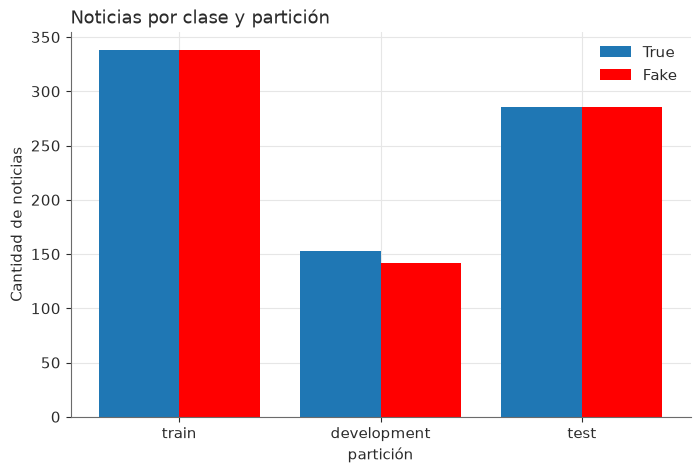

Category,Fake,True,% Fake
particion,,,
train,338,338,50.0
development,142,153,48.1
test,286,286,50.0


In [23]:
clases = pd.crosstab(corpus['particion'], corpus['Category']).loc[particiones]
x = np.arange(len(clases))

fig, ax = plt.subplots(figsize = (8, 5))
ax.bar(x - 0.2, clases['True'], width = 0.4, color = COLORES_CLASE['True'], label = 'True')
ax.bar(x + 0.2, clases['Fake'], width = 0.4, color = COLORES_CLASE['Fake'], label = 'Fake')
ax.set_xticks(x, clases.index)
ax.set_xlabel('partición')
ax.set_ylabel('Cantidad de noticias')
ax.set_title('Noticias por clase y partición')
ax.legend()
guardar(fig, '6_1_clases_por_particion')
plt.show()

clases['% Fake'] = (100 * clases['Fake'] / clases[['Fake', 'True']].sum(axis = 1)).round(1)
clases

**Qué se observa.** Ninguna clase domina: 50.0 % de falsas en `train` y en `test` y 48.1 % en `development` (142 de 295). **No hace falta rebalancear; el balance permite comparar la F1 de fake contra un baseline de clase mayoritaria sin distorsión.**

<a id="seccion-7"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 7: Temas</span></div>

> **Qué se hace:** comparamos la distribución de temas entre versiones y la proporción de falsas dentro de cada tema.
>
> **Qué se espera ver:** temas casi distintos entre versiones y un balance de clases que se mantiene dentro de cada tema.

### 7.1 Temas por versión (Figura 7.1)

Usamos proporciones, no conteos, porque las versiones tienen tamaños distintos.

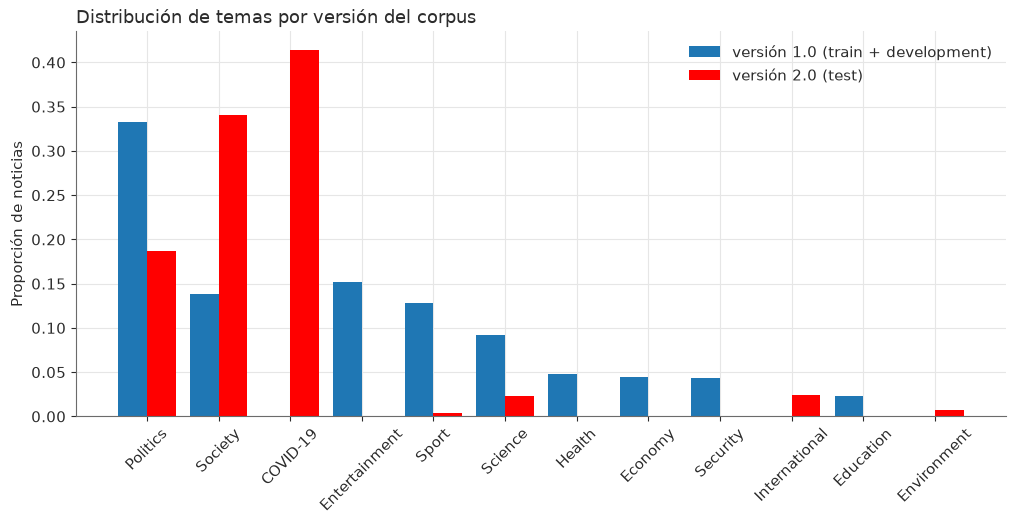

In [24]:
temas = pd.crosstab(corpus['Topic'], corpus['version'], normalize = 'columns')
temas = temas.loc[temas.sum(axis = 1).sort_values(ascending = False).index]
x = np.arange(len(temas))

fig, ax = plt.subplots(figsize = (12, 5))
ax.bar(x - 0.2, temas['1.0'], width = 0.4, label = 'versión 1.0 (train + development)')
ax.bar(x + 0.2, temas['2.0'], width = 0.4, color = 'red', label = 'versión 2.0 (test)')
ax.set_xticks(x, temas.index, rotation = 45)
ax.set_ylabel('Proporción de noticias')
ax.set_title('Distribución de temas por versión del corpus')
ax.legend()
guardar(fig, '7_1_temas_por_version')
plt.show()

**Tabla 7.1.** Temas exclusivos de cada versión.

In [25]:
temas_v1, temas_v2 = set(corpus.loc[corpus['version'] == '1.0', 'Topic']), set(test['Topic'])
pd.Series({'solo en la versión 1.0': ', '.join(sorted(temas_v1 - temas_v2)),
           'solo en la versión 2.0': ', '.join(sorted(temas_v2 - temas_v1)),
           'en ambas': ', '.join(sorted(temas_v1 & temas_v2))}, name = 'temas').to_frame()

,temas
solo en la versión 1.0,"Economy, Education, Entertainment, Health, Security"
solo en la versión 2.0,"COVID-19, Environment, International"
en ambas,"Politics, Science, Society, Sport"


### 7.2 Proporción de falsas por tema (Figura 7.2)

Un mapa de calor permite leer tema × partición a la vez; cada celda muestra la proporción de falsas y su n.

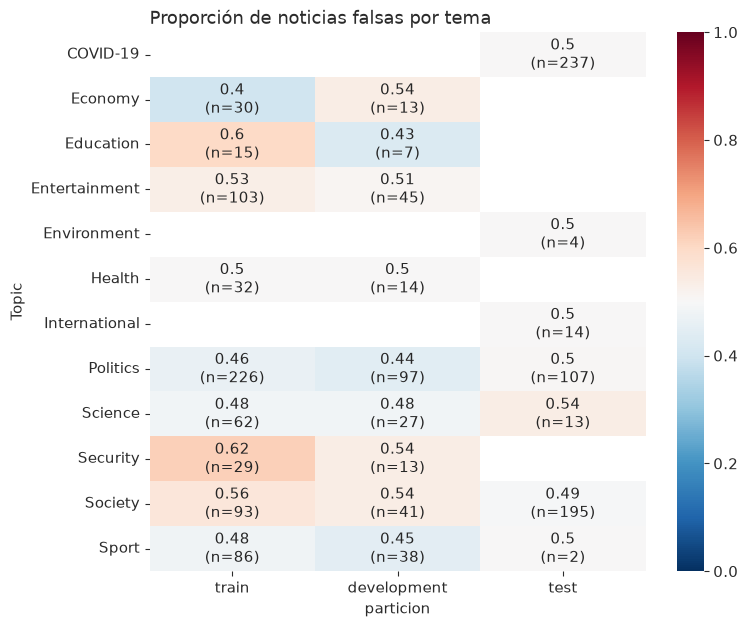

In [26]:
fake_tema = corpus.assign(fake = corpus['Category'] == 'Fake').pivot_table(index = 'Topic', columns = 'particion',
                                                                          values = 'fake', aggfunc = 'mean')[particiones]
n_tema = corpus.pivot_table(index = 'Topic', columns = 'particion', values = 'Id', aggfunc = 'count')[particiones]
etiquetas_celda = fake_tema.round(2).astype(str) + '\n(n=' + n_tema.fillna(0).astype(int).astype(str) + ')'

fig, ax = plt.subplots(figsize = (8, 7))
sns.heatmap(fake_tema, annot = etiquetas_celda.where(n_tema.notnull(), ''), fmt = '', cmap = 'RdBu_r', vmin = 0, vmax = 1, ax = ax)
ax.set_title('Proporción de noticias falsas por tema')
ax.grid(False)
guardar(fig, '7_2_falsas_por_tema')
plt.show()

**Qué se observa.** Solo 4 temas aparecen en ambas versiones (Politics, Science, Society y Sport). En `test`, COVID-19 tiene 237 noticias (41.4 %), y Sport solo 2. Dentro de cada tema la proporción de falsas se mantiene cerca de 0.5: en `test` va de 0.49 (Society, n = 195) a 0.54 (Science, n = 13). Los extremos de `train` son Security, con 0.62 (n = 29), y Economy, con 0.40 (n = 30). **El tema casi no predice la clase (V de Cramér ≤ 0.10, Tabla 8.3), así que usarlo para agrupar o para analizar errores por tema no introduce un atajo.**

<a id="seccion-8"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 8: Fuentes</span></div>

> **Qué se hace:** medimos qué tanto determina la fuente la clase y cuántas fuentes del test aparecen en train.
>
> **Qué se espera ver:** fuentes que publican una sola clase (riesgo de atajo) y pocas fuentes compartidas entre versiones.

#### Glosario de la sección
* **Pureza:** % de noticias que vienen de una fuente que publica una sola clase.
* **V de Cramér:** fuerza de asociación entre dos variables categóricas, de 0 (ninguna) a 1 (una determina a la otra).

### 8.1 Fuentes más frecuentes (Figura 8.1)

Normalizamos el nombre de la fuente (minúsculas y sin espacios) y extraemos el dominio del enlace.

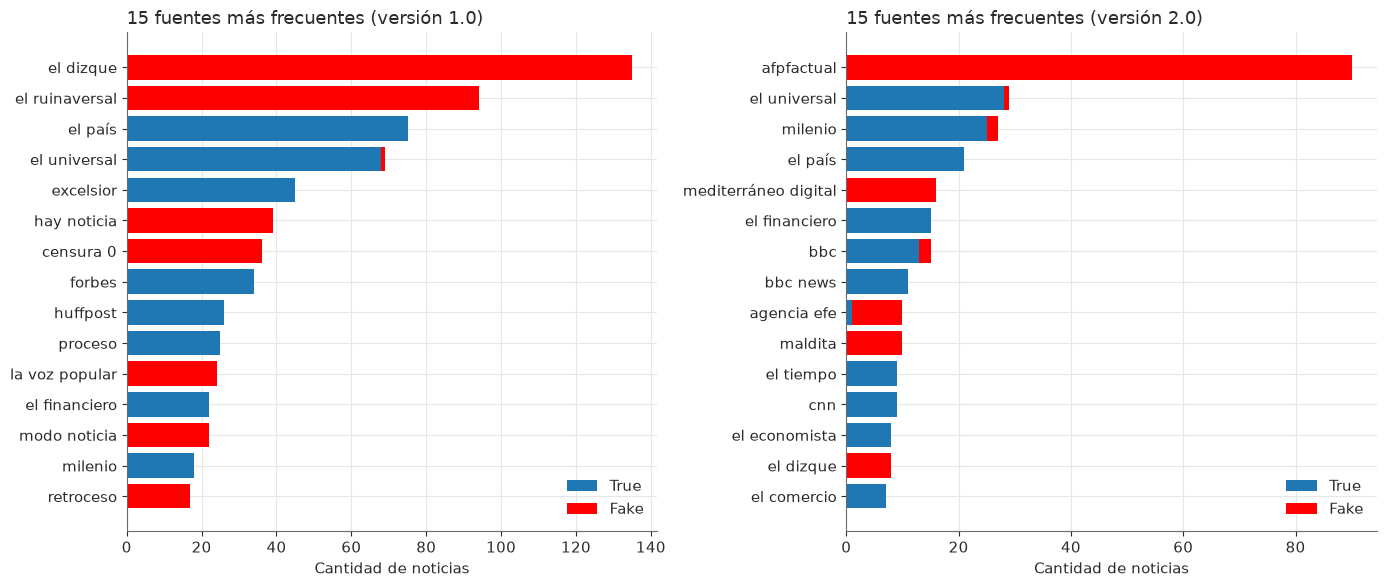

In [27]:
corpus['fuente'] = corpus['Source'].str.strip().str.lower()
corpus['dominio'] = corpus['Link'].str.extract(r'https?://(?:www\.)?([^/]+)', expand = False)

fig = plt.figure(figsize = (14, 6))
for i, version in enumerate(['1.0', '2.0']):
    df = corpus[corpus['version'] == version]
    top = pd.crosstab(df['fuente'], df['Category'])
    top = top.loc[top.sum(axis = 1).sort_values().index[-15:]]
    ax = fig.add_subplot(1, 2, i + 1)
    ax.barh(top.index, top['True'], color = COLORES_CLASE['True'], label = 'True')
    ax.barh(top.index, top['Fake'], left = top['True'], color = COLORES_CLASE['Fake'], label = 'Fake')
    ax.set_xlabel('Cantidad de noticias')
    ax.set_title(f'15 fuentes más frecuentes (versión {version})')
    ax.legend()
fig.tight_layout()
guardar(fig, '8_1_fuentes_frecuentes')
plt.show()

### 8.2 Pureza de la fuente y del dominio (Tabla 8.1)

In [28]:
def pureza(df, columna):
    '''
    Función que mide qué tanto determina una columna la clase de la noticia

    inputs:
    --------
        df (pandas.DataFrame): Registros a evaluar
        columna (str): Columna categórica ('fuente' o 'dominio')

    outputs:
    --------
        pandas.Series: Valores distintos y % de noticias cuyo valor publica una sola clase
    '''
    df = df.dropna(subset = [columna])
    una_clase = df.groupby(columna)['Category'].transform('nunique') == 1
    return pd.Series({'valores distintos': df[columna].nunique(), '% noticias en valores de una sola clase': round(100 * una_clase.mean(), 1)})

**Tabla 8.1.** Pureza por partición.

In [29]:
pd.DataFrame({(p, c): pureza(corpus[corpus['particion'] == p], c) for p in particiones for c in ['fuente', 'dominio']})

train         development          \
                                        fuente dominio      fuente dominio   
valores distintos                        122.0   111.0        72.0    72.0   
% noticias en valores de una sola clase   93.0    91.6       100.0    98.3   

                                          test          
                                        fuente dominio  
valores distintos                        199.0   213.0  
% noticias en valores de una sola clase   81.1    77.6

### 8.3 Fuentes compartidas con train (Tabla 8.2)

**Tabla 8.2.** Noticias cuya fuente normalizada aparece en `train`.

In [30]:
fuentes_train = set(train['Source'].str.strip().str.lower())
pd.Series({p: round(100 * corpus.loc[corpus['particion'] == p, 'fuente'].isin(fuentes_train).mean(), 1)
           for p in ['development', 'test']}, name = '% con fuente vista en train').to_frame()

,% con fuente vista en train
development,90.5
test,34.3


**Qué se observa.** La fuente casi determina la clase: en la versión 1.0, más del 90 % de las noticias proviene de un medio que solo publica una de las dos clases. Las falsas vienen sobre todo de sitios satíricos o de rumores (*El Dizque*, *El Ruinaversal*, *Hay noticia*, *Censura 0*) y las verdaderas de periódicos establecidos (*El País*, *Excelsior*, *El Universal*). En la versión 2.0, los 90 registros de *AFPFactual* son falsos porque la fuente anotada es el verificador que desmintió la publicación; lo mismo pasa con *Maldita* y casi todos los de *Agencia EFE*. **`Source` y `Link` no se usan como variables de entrada, y aun usando solo el texto un modelo puede aprender el estilo de cada medio; por eso los folds se agrupan por fuente.**

### 8.4 V de Cramér entre fuente y clase (Tabla 8.3)

Cuantificamos la asociación de la Tabla 8.1 y la comparamos con la del tema:

$$V = \sqrt{\frac{\chi^2}{n\,(\min(r, c) - 1)}}$$

* $\chi^2$: estadístico de la prueba de independencia sobre la tabla de contingencia.
* $n$: número de noticias; $r$, $c$: número de filas y columnas de la tabla.

⚠️ Con muchas fuentes de pocas noticias, la mayoría de las celdas tiene frecuencia esperada menor que 5: el valor p del χ² es solo orientativo y $V$ tiende a sobreestimar la asociación. Por eso reportamos el % de celdas con esperado < 5.

**Tabla 8.3.** V de Cramér de la fuente y del tema con la clase.

In [31]:
def v_cramer(x, y):
    '''
    Función que calcula la V de Cramér entre dos variables categóricas

    inputs:
    --------
        x (pandas.Series): Primera variable
        y (pandas.Series): Segunda variable

    outputs:
    --------
        pandas.Series: Categorías de x, V de Cramér, valor p del χ² y % de celdas con esperado < 5
    '''
    tabla = pd.crosstab(x, y)
    chi2, p, _, esperados = stats.chi2_contingency(tabla, correction = False)
    v = np.sqrt(chi2 / (tabla.values.sum() * (min(tabla.shape) - 1)))
    return pd.Series({'categorías': tabla.shape[0], 'V de Cramér': round(v, 3), 'p (χ², orientativo)': p,
                      '% celdas con esperado < 5': round(100 * (esperados < 5).mean(), 1)})

In [32]:
cramer = pd.DataFrame({(p, c): v_cramer(df[c].fillna('sin fuente'), df['Category'])
                       for p in particiones for df in [corpus[corpus['particion'] == p]] for c in ['fuente', 'Topic']}).T
guardar_csv(cramer, 'eda_cramer', index = True)
cramer

categorías  V de Cramér  p (χ², orientativo)  \
train       fuente       122.0        0.996         6.166230e-77   
            Topic          9.0        0.099         5.748478e-01   
development fuente        72.0        1.000         4.353201e-29   
            Topic          9.0        0.079         9.856248e-01   
test        fuente       200.0        0.956         7.627802e-31   
            Topic          7.0        0.015         9.999495e-01   

                    % celdas con esperado < 5  
train       fuente                       85.2  
            Topic                         0.0  
development fuente                       90.3  
            Topic                        11.1  
test        fuente                       95.0  
            Topic                        28.6

**Qué se observa.** La asociación entre fuente y clase es casi total: V = 0.996 en `train`, 1.000 en `development` y 0.956 en `test`. Con el tema, V = 0.099, 0.079 y 0.015. ⚠️ En la fuente, entre el 85.2 % y el 95.0 % de las celdas tienen frecuencia esperada < 5 (122 fuentes para 676 noticias en `train`), así que el valor p es orientativo y V está inflada. Aun así, coincide con la pureza de la Tabla 8.1 (93.0 % en `train`). **La fuente es un atajo casi perfecto en los datos de entrenamiento; agrupar los folds por fuente es indispensable para no medir cuánto reconoce el modelo los medios. Kiesel et al. [6] documentaron el mismo problema en SemEval-2019 Task 4: los modelos entrenados con etiquetas por medio aprendían el estilo del medio.**

<a id="seccion-9"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 9: Longitud de los textos</span></div>

> **Qué se hace:** medimos la longitud en palabras por partición y clase, probamos si la diferencia entre clases es significativa y buscamos longitudes atípicas.
>
> **Qué se espera ver:** noticias falsas más cortas en todas las particiones y algunos textos muy largos que son legítimos.

#### Glosario de la sección
* **Mann-Whitney U:** prueba no paramétrica que compara si los valores de un grupo tienden a ser mayores que los de otro; no supone normalidad.
* **Correlación biserial de rangos (r):** tamaño de efecto de Mann-Whitney, de −1 a 1; 0 indica que no hay diferencia.
* **Bonferroni:** corrección por pruebas múltiples: se multiplica cada valor p por el número de pruebas.
* **IQR:** rango intercuartílico (Q3 − Q1); se marca como atípico lo que supera Q3 + 1.5·IQR.

### 9.1 Longitud por partición (Tabla 9.1 y Figura 9.1)

Medimos en palabras separadas por espacios. En los diagramas de caja omitimos los atípicos para que la escala sea legible (se analizan en 9.4).

**Tabla 9.1.** Estadísticas de la longitud del texto en palabras.

In [33]:
corpus['n_palabras'] = corpus['Text'].str.split().str.len()
corpus['n_palabras_titular'] = corpus['Headline'].str.split().str.len()
corpus.groupby('particion', sort = False)['n_palabras'].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
particion,,,,,,,,
train,676.0,377.9,255.9,20.0,223.0,314.5,458.2,2081.0
development,295.0,417.2,337.0,51.0,229.0,321.0,481.5,2566.0
test,572.0,521.3,438.0,47.0,250.0,398.5,653.0,4006.0


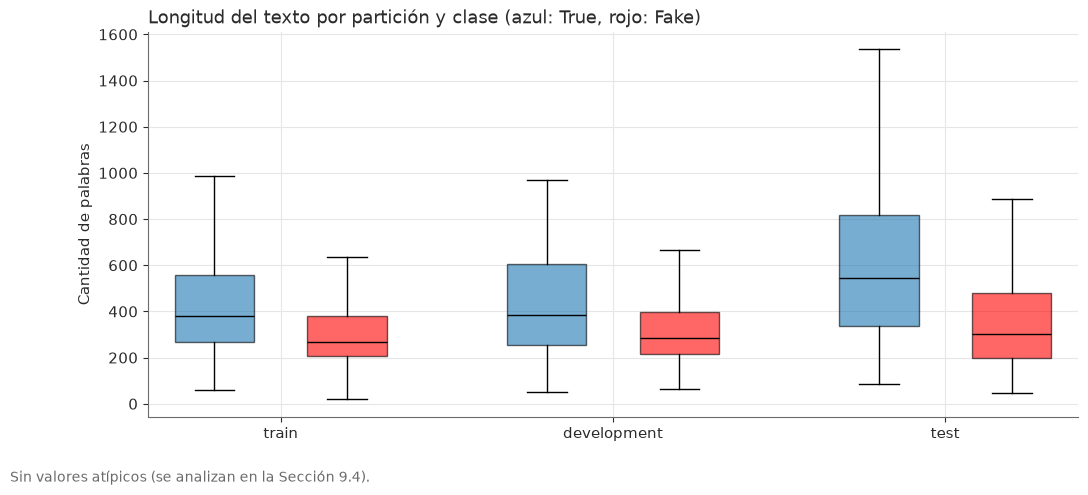

In [34]:
fig, ax = plt.subplots(figsize = (12, 5))
pos = 0
for p in particiones:
    for clase in ['True', 'Fake']:
        datos = corpus.loc[(corpus['particion'] == p) & (corpus['Category'] == clase), 'n_palabras']
        caja = ax.boxplot(datos, positions = [pos], widths = 0.6, showfliers = False, patch_artist = True,
                          medianprops = {'color': 'black'})
        caja['boxes'][0].set_facecolor(COLORES_CLASE[clase])
        caja['boxes'][0].set_alpha(0.6)
        pos += 1
    pos += 0.5
ax.set_xticks([0.5, 3, 5.5], particiones)
ax.set_ylabel('Cantidad de palabras')
ax.set_title('Longitud del texto por partición y clase (azul: True, rojo: Fake)')
fig.text(0.01, -0.02, 'Sin valores atípicos (se analizan en la Sección 9.4).', color = TINTA_SUAVE, fontsize = 10)
guardar(fig, '9_1_longitud_por_clase')
plt.show()

### 9.2 Medianas por clase (Tabla 9.2)

**Tabla 9.2.** Mediana de palabras del texto y del titular por partición y clase.

In [35]:
corpus.groupby(['particion', 'Category'], sort = False)[['n_palabras', 'n_palabras_titular']].median().unstack()

n_palabras        n_palabras_titular      
Category          Fake   True               Fake  True
particion                                             
train            269.0  382.0               12.0  10.0
development      283.5  385.0               12.0  10.0
test             301.0  545.0               13.0  12.0

### 9.3 Prueba de Mann-Whitney para la longitud (Tabla 9.3)

Comparamos las longitudes de falsas y verdaderas con Mann-Whitney porque las distribuciones son asimétricas. El tamaño de efecto es la correlación biserial de rangos:

$$r = \frac{2\,U_{fake}}{n_{fake}\,n_{true}} - 1$$

* $U_{fake}$: estadístico U de las noticias falsas.
* $n_{fake}$, $n_{true}$: tamaño de cada grupo.
* $r > 0$ indica que las falsas tienden a ser más largas; $r < 0$, más cortas. Como referencia, $|r| \approx 0.1$ es un efecto pequeño, $0.3$ mediano y $0.5$ grande.

Aplicamos Bonferroni sobre las 6 pruebas de la tabla (3 particiones × texto y titular). Los 72 titulares vacíos de `test` quedan fuera de la prueba del titular.

**Tabla 9.3.** Mann-Whitney de la longitud entre clases.

In [36]:
def mann_whitney(df, columna):
    '''
    Función que compara una variable numérica entre noticias falsas y verdaderas con Mann-Whitney

    inputs:
    --------
        df (pandas.DataFrame): Registros con 'Category' y la columna a comparar
        columna (str): Variable numérica

    outputs:
    --------
        pandas.Series: Tamaños, medianas, U, valor p y correlación biserial de rangos (r > 0: falsas mayores)
    '''
    falsas = df.loc[df['Category'] == 'Fake', columna].dropna()
    verdaderas = df.loc[df['Category'] == 'True', columna].dropna()
    u, p = stats.mannwhitneyu(falsas, verdaderas, alternative = 'two-sided')
    return pd.Series({'n Fake': len(falsas), 'n True': len(verdaderas), 'mediana Fake': falsas.median(),
                      'mediana True': verdaderas.median(), 'U': u, 'p': p, 'r': 2 * u / (len(falsas) * len(verdaderas)) - 1})

def con_bonferroni(tabla):
    '''
    Función que agrega el valor p corregido por Bonferroni y la decisión con alfa = 0.05

    inputs:
    --------
        tabla (pandas.DataFrame): Resultados con la columna 'p'

    outputs:
    --------
        pandas.DataFrame: La misma tabla con 'p Bonferroni' y 'significativa'
    '''
    tabla = tabla.copy()
    tabla['p Bonferroni'] = (tabla['p'] * len(tabla)).clip(upper = 1)
    tabla['significativa'] = np.where(tabla['p Bonferroni'] < 0.05, '✅', '❌')
    return tabla

In [37]:
mw_longitud = con_bonferroni(pd.DataFrame({(p, c): mann_whitney(corpus[corpus['particion'] == p], c)
                                           for p in particiones for c in ['n_palabras', 'n_palabras_titular']}).T)
guardar_csv(mw_longitud, 'eda_mann_whitney_longitud', index = True)
mw_longitud.round({'mediana Fake': 1, 'mediana True': 1, 'r': 3}).style.format({'p': '{:.1e}', 'p Bonferroni': '{:.1e}', 'U': '{:,.0f}'})

**Qué se observa.** Las falsas son más cortas en las tres particiones, con un efecto mediano y estable: r = −0.37 en `train` (mediana de 269 contra 382 palabras), −0.30 en `development` y −0.44 en `test` (301 contra 545). Las 3 diferencias son significativas tras Bonferroni (p corregido ≤ 0.0001). El titular de las falsas es más largo en la versión 1.0 (r = 0.32 y 0.42). En `test` el efecto es pequeño (r = 0.11) y no es significativo tras la corrección (p = 0.20), con n = 214 falsas porque 72 no tienen titular. **La longitud del texto es una señal real y consistente entre versiones; vale la pena incluirla como rasgo denso. La del titular no se sostiene en el test.**

### 9.4 Longitudes atípicas (Tabla 9.4)

Aplicamos el criterio IQR por versión, porque los textos de la 2.0 son más largos en general. **Tabla 9.4.** Textos con longitud atípica por versión y clase.

In [38]:
def limites_iqr(serie):
    '''
    Función que calcula los límites inferior y superior del criterio IQR

    inputs:
    --------
        serie (pandas.Series): Variable numérica

    outputs:
    --------
        tuple: (límite inferior, límite superior)
    '''
    q1, q3 = serie.quantile([0.25, 0.75])
    return q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)

limites = {v: limites_iqr(corpus.loc[corpus['version'] == v, 'n_palabras']) for v in ['1.0', '2.0']}
corpus['longitud_atipica'] = corpus.apply(lambda r: not (limites[r['version']][0] <= r['n_palabras'] <= limites[r['version']][1]), axis = 1)
atipicos_longitud = corpus.groupby(['version', 'Category'])['longitud_atipica'].agg(['size', 'sum', 'mean'])
atipicos_longitud.columns = ['noticias', 'atípicas', '%']
atipicos_longitud['%'] = (100 * atipicos_longitud['%']).round(1)
atipicos_longitud['límite superior (palabras)'] = [round(limites[v][1]) for v, _ in atipicos_longitud.index]
atipicos_longitud

noticias  atípicas     %  límite superior (palabras)
version Category                                                      
1.0     Fake           480         4   0.8                         823
        True           491        51  10.4                         823
2.0     Fake           286        11   3.8                        1258
        True           286        22   7.7                        1258

**Qué se observa.** Con el criterio IQR por versión, 55 noticias de la 1.0 (más de 823 palabras) y 33 de la 2.0 (más de 1,258) son atípicas por longitud. Casi todas las de la 1.0 son verdaderas: 51 (10.4 % de las verdaderas) contra 4 falsas (0.8 %). Son notas largas de periódicos establecidos, no errores. No hay atípicos por debajo del límite inferior. **Se conservan todas; eliminarlas quitaría sobre todo verdaderas y sesgaría las clases. TF-IDF no requiere truncar; un transformer sí (planeado).**

<a id="seccion-10"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 10: Rasgos de estilo</span></div>

> **Qué se hace:** calculamos rasgos superficiales asociados con el sensacionalismo y probamos si difieren entre clases dentro de cada versión.
>
> **Qué se espera ver:** más signos de exclamación e interrogación en las falsas de ambas versiones.

### 10.1 Cálculo de los rasgos (Tabla 10.1)

Calculamos la proporción de letras mayúsculas y la frecuencia de exclamaciones, interrogaciones y comillas por cada mil caracteres. En la versión 1.0 la proporción de mayúsculas está inflada porque el texto empieza con el titular en mayúsculas, así que se calcula sin la primera línea.

**Tabla 10.1.** Media de cada rasgo por versión y clase.

In [39]:
cuerpo = corpus['Text'].where(corpus['version'] == '2.0', corpus['Text'].str.split('\n', n = 1).str[-1])
n_car = cuerpo.str.len()

corpus['% mayúsculas'] = 100 * cuerpo.str.count(r'[A-ZÁÉÍÓÚÑ]') / cuerpo.str.count(r'[A-Za-zÁÉÍÓÚÑáéíóúñ]')
corpus['exclamaciones'] = 1000 * cuerpo.str.count(r'[!¡]') / n_car
corpus['interrogaciones'] = 1000 * cuerpo.str.count(r'[?¿]') / n_car
corpus['comillas'] = 1000 * cuerpo.str.count(r'["“”«»]') / n_car
rasgos = ['% mayúsculas', 'exclamaciones', 'interrogaciones', 'comillas']
corpus.groupby(['version', 'Category'])[rasgos].mean().round(2)

% mayúsculas  exclamaciones  interrogaciones  comillas
version Category                                                        
1.0     Fake              3.92           0.21             0.35      3.44
        True              5.36           0.09             0.15      3.14
2.0     Fake              4.94           0.51             0.86      3.00
        True              2.83           0.05             0.27      3.22

### 10.2 Rasgos por clase (Figura 10.1)

Barras con intervalo de confianza del 95 % por bootstrap (semilla fija).

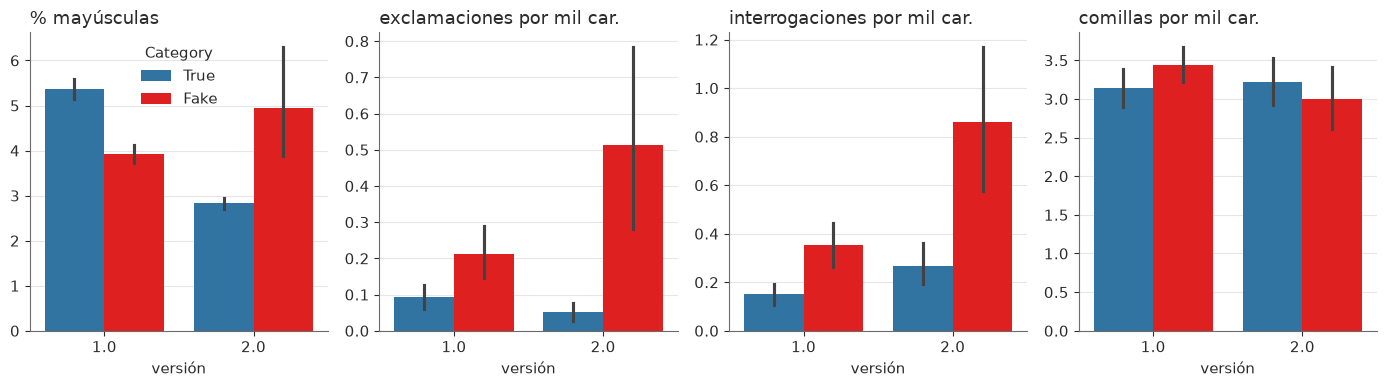

In [40]:
fig = plt.figure(figsize = (14, 4))
for i, rasgo in enumerate(rasgos):
    ax = fig.add_subplot(1, 4, i + 1)
    sns.barplot(data = corpus, x = 'version', y = rasgo, hue = 'Category', palette = COLORES_CLASE,
                hue_order = ['True', 'Fake'], errorbar = ('ci', 95), seed = SEMILLA, ax = ax)
    ax.set_title(rasgo if i == 0 else f'{rasgo} por mil car.')
    ax.set_ylabel('')
    ax.set_xlabel('versión')
    if i > 0:
        ax.get_legend().remove()
fig.tight_layout()
guardar(fig, '10_1_rasgos_de_estilo')
plt.show()

### 10.3 Prueba de Mann-Whitney para los rasgos (Tabla 10.2)

Misma prueba y tamaño de efecto que en 9.3, con Bonferroni sobre las 8 pruebas (2 versiones × 4 rasgos).

**Tabla 10.2.** Mann-Whitney de los rasgos de estilo entre clases.

In [41]:
mw_estilo = con_bonferroni(pd.DataFrame({(v, r): mann_whitney(corpus[corpus['version'] == v], r)
                                         for v in ['1.0', '2.0'] for r in rasgos}).T)
guardar_csv(mw_estilo, 'eda_mann_whitney_estilo', index = True)
mw_estilo.round({'mediana Fake': 2, 'mediana True': 2, 'r': 3}).style.format({'p': '{:.1e}', 'p Bonferroni': '{:.1e}', 'U': '{:,.0f}'})

**Qué se observa.** Solo 4 de las 8 diferencias son significativas tras Bonferroni, y casi todas con efecto pequeño. La proporción de mayúsculas se invierte entre versiones: en la 1.0 es menor en las falsas (r = −0.42, efecto mediano) y en la 2.0 es mayor (r = 0.19). Las exclamaciones solo distinguen en la 2.0 (r = 0.12, p corregido = 0.0003); en la 1.0, r = 0.02 y p corregido = 1. Las interrogaciones no son significativas en ninguna versión. La mediana de exclamaciones e interrogaciones es 0 en todos los grupos: la mayoría de las noticias no usa esos signos y la diferencia de medias de la Tabla 10.1 la producen pocos textos. **Esto corrige la conclusión del EDA anterior ("más exclamaciones e interrogaciones en ambas versiones"): ningún rasgo de estilo es estable entre versiones, y las mayúsculas cambian de dirección, así que hay que probar los rasgos de estilo en validación cruzada antes de confiar en ellos.**

<a id="seccion-11"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 11: Vocabulario</span></div>

> **Qué se hace:** buscamos las palabras que distinguen a cada clase y medimos cuánto vocabulario del test es nuevo.
>
> **Qué se espera ver:** palabras distintivas diferentes en cada versión y una fracción grande de vocabulario nuevo en el test.

Tokenizamos en minúsculas conservando solo palabras alfabéticas y quitamos las marcas de anonimización y las palabras vacías. Para cada palabra usamos el logaritmo de la razón entre su frecuencia documental relativa en falsas y en verdaderas, con suavizado de Laplace, considerando solo palabras presentes en al menos 10 noticias.

In [42]:
def tokenizar(texto):
    '''
    Función que convierte un texto en una lista de palabras útiles

    inputs:
    --------
        texto (str): Texto de la noticia

    outputs:
    --------
        list: Palabras en minúsculas, sin marcas de anonimización ni palabras vacías
    '''
    texto = re.sub(r'\*[A-Z]+\*', ' ', texto).lower()
    return [t for t in re.findall(r'[a-záéíóúñü]+', texto) if t not in STOPWORDS_ES and len(t) > 2]

def log_razon(df, minimo = 10):
    '''
    Función que calcula el logaritmo de la razón Fake / True de la frecuencia documental relativa de cada palabra

    inputs:
    --------
        df (pandas.DataFrame): Registros con la columna 'tokens'
        minimo (int): Cantidad mínima de noticias en las que debe aparecer una palabra

    outputs:
    --------
        pandas.Series: Log-razón por palabra (positiva: más propia de Fake)
    '''
    cuentas = {c: Counter(t for ts in df.loc[df['Category'] == c, 'tokens'] for t in set(ts)) for c in ['Fake', 'True']}
    tabla = pd.DataFrame(cuentas).fillna(0)
    tabla = tabla[tabla.sum(axis = 1) >= minimo]
    n_docs = df['Category'].value_counts()
    frec = (tabla + 1) / (n_docs[tabla.columns] + 2)
    return np.log(frec['Fake'] / frec['True']).sort_values()

corpus['tokens'] = corpus['Text'].apply(tokenizar)

### 11.1 Palabras distintivas (Figura 11.1)

Barras horizontales con las 12 palabras más extremas de cada lado.

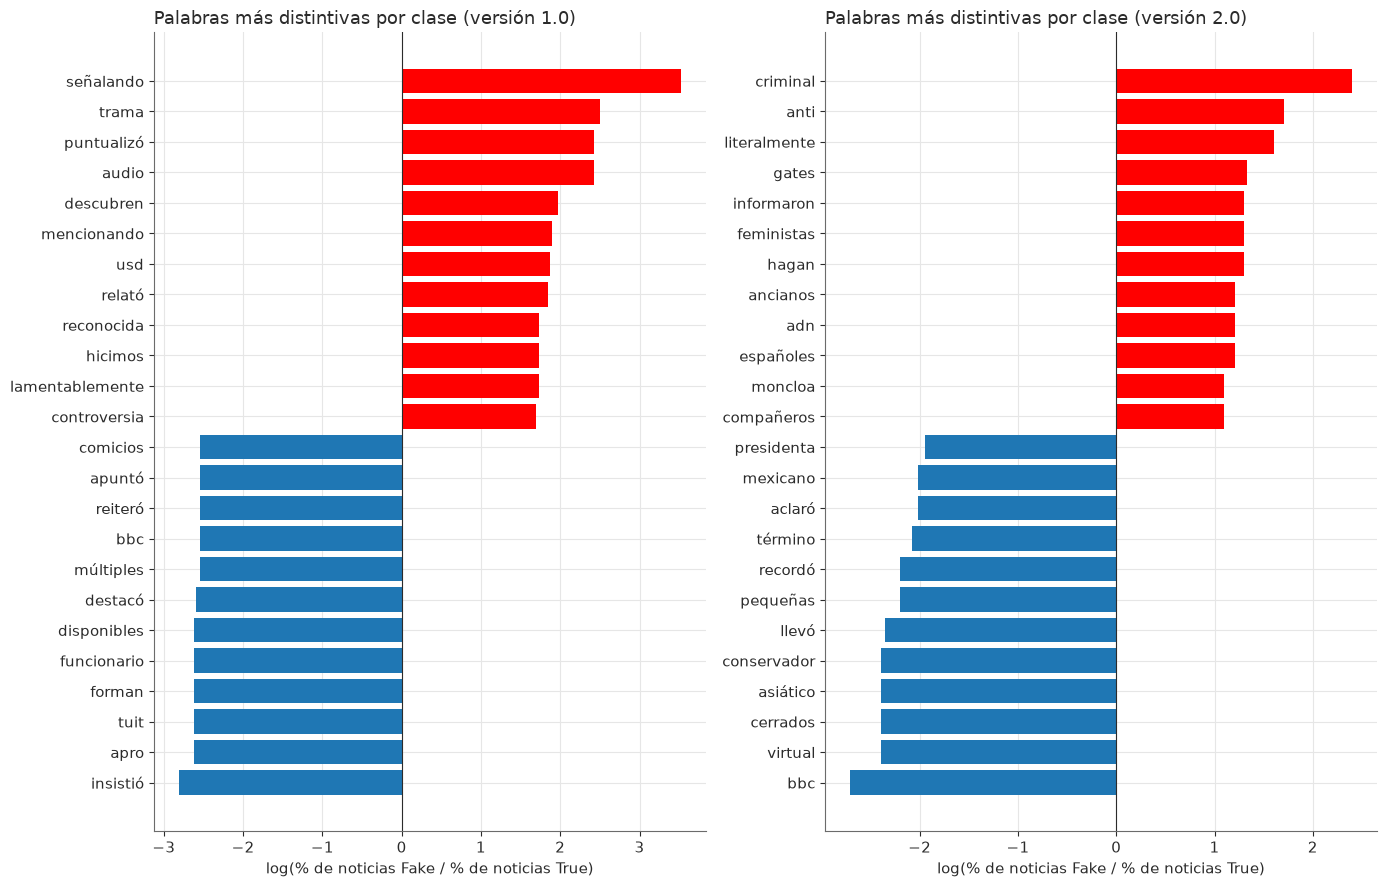

In [43]:
fig = plt.figure(figsize = (14, 9))
for i, version in enumerate(['1.0', '2.0']):
    lr = log_razon(corpus[corpus['version'] == version])
    extremos = pd.concat([lr.head(12), lr.tail(12)])
    ax = fig.add_subplot(1, 2, i + 1)
    ax.barh(extremos.index, extremos.values, color = np.where(extremos > 0, COLORES_CLASE['Fake'], COLORES_CLASE['True']))
    ax.axvline(0, color = TINTA, linewidth = 0.8)
    ax.set_xlabel('log(% de noticias Fake / % de noticias True)')
    ax.set_title(f'Palabras más distintivas por clase (versión {version})')
fig.tight_layout()
guardar(fig, '11_1_palabras_distintivas')
plt.show()

### 11.2 Cobertura del vocabulario del test (Tabla 11.1)

**Tabla 11.1.** Tamaño del vocabulario y vocabulario del test ausente en la versión 1.0.

In [44]:
vocab_v1 = Counter(t for ts in corpus.loc[corpus['version'] == '1.0', 'tokens'] for t in ts)
tokens_test = [t for ts in corpus.loc[corpus['version'] == '2.0', 'tokens'] for t in ts]
vocab_test = set(tokens_test)
pct_vocab_nuevo = round(100 * len(vocab_test - set(vocab_v1)) / len(vocab_test), 1)
pd.Series({'vocabulario de la versión 1.0': len(vocab_v1), 'vocabulario de test': len(vocab_test),
           '% de palabras distintas de test ausentes en la 1.0': pct_vocab_nuevo,
           '% de ocurrencias de test ausentes en la 1.0': round(100 * np.mean([t not in vocab_v1 for t in tokens_test]), 1),
           '% del vocabulario de la 1.0 que aparece una sola vez': round(100 * np.mean([n == 1 for n in vocab_v1.values()]), 1)},
          name = 'valor').to_frame()

,valor
vocabulario de la versión 1.0,29903.0
vocabulario de test,25347.0
% de palabras distintas de test ausentes en la 1.0,45.1
% de ocurrencias de test ausentes en la 1.0,16.7
% del vocabulario de la 1.0 que aparece una sola vez,48.5


**Tabla 11.2.** Palabras más frecuentes de test ausentes en la versión 1.0 (solo conteos).

In [45]:
pd.DataFrame(Counter(t for t in tokens_test if t not in vocab_v1).most_common(15), columns = ['palabra', 'ocurrencias en test'])

,palabra,ocurrencias en test
0,covid,662
1,coronavirus,400
2,cov,133
3,biden,104
4,anticuerpos,98
5,vacunación,97
6,wuhan,69
7,cubrebocas,55
8,bitcoin,49
9,dempster,45


**Qué se observa.** El 45.1 % de las palabras distintas del test no aparece en la versión 1.0, y esas palabras suman el 16.7 % de las ocurrencias. Las más frecuentes son del tema nuevo (*covid*, 662; *coronavirus*, 400; *vacunación*, 97). El 48.5 % del vocabulario de la 1.0 aparece una sola vez. Estas cifras difieren ligeramente de las del EDA anterior (44.5 % y 14.7 %) porque cambió la versión de la lista de palabras vacías (`stopwordsiso` 0.7.1); el orden de magnitud es el mismo. **Un modelo de palabras verá casi la mitad del vocabulario del test por primera vez; los n-gramas de caracteres, que comparten subcadenas como *vacun-*, deberían degradarse menos.**

<a id="seccion-12"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 12: Casi duplicados y pares de un mismo hecho</span></div>

> **Qué se hace:** buscamos textos casi idénticos (incluso entre versiones), titulares repetidos e intentamos reconstruir los pares verdadera–falsa con que se armó el corpus.
>
> **Qué se espera ver:** pocos casi duplicados, alguno que cruza particiones (fuga), y pares que solo se pueden reconstruir en parte.

⚠️ El TF-IDF de esta sección se ajusta con todo el corpus porque solo perfila; los modelos ajustan su TF-IDF dentro de cada fold.

#### Glosario de la sección
* **TF-IDF:** representación de un texto como vector de pesos de palabras: frecuentes en el texto y raras en el corpus pesan más.
* **Similitud coseno:** coseno del ángulo entre dos vectores TF-IDF; 1 = mismo vocabulario en las mismas proporciones.
* **Razón de Levenshtein:** $(1 - d / \text{longitud mayor}) \times 100$, donde $d$ es el número mínimo de ediciones de caracteres para convertir un texto en el otro.
* **Mejor pareja mutua:** una falsa y una verdadera tales que cada una es la más parecida a la otra.

### 12.1 Casi duplicados (Tabla 12.1)

Comparamos titular + texto con TF-IDF y similitud coseno, quitando antes las marcas de anonimización para que la versión 1.0 y la 2.0 sean comparables. Los pares con coseno ≥ `UMBRAL_CASI_DUPLICADO` (0.8) se confirman con la razón de Levenshtein sobre los primeros 2,000 caracteres.

**Tabla 12.1.** Pares de noticias con coseno ≥ 0.8 (solo IDs).

In [46]:
textos_comparables = (corpus['Headline'].fillna('') + ' ' + corpus['Text']).str.replace(r'\*[A-Z]+\*', ' ', regex = True)
similitud = cosine_similarity(TfidfVectorizer(sublinear_tf = True).fit_transform(textos_comparables))
a, b = np.where(np.triu(similitud, k = 1) >= UMBRAL_CASI_DUPLICADO)

casi_duplicados = pd.DataFrame({'Id_a': corpus['Id'].values[a], 'particion_a': corpus['particion'].values[a], 'clase_a': corpus['Category'].values[a],
                                'Id_b': corpus['Id'].values[b], 'particion_b': corpus['particion'].values[b], 'clase_b': corpus['Category'].values[b],
                                'coseno': similitud[a, b].round(3),
                                'levenshtein': [round(fuzz.ratio(textos_comparables[i][:2000], textos_comparables[j][:2000]), 1) for i, j in zip(a, b)]})
casi_duplicados['misma clase'] = np.where(casi_duplicados['clase_a'] == casi_duplicados['clase_b'], '✅', '❌')
casi_duplicados['cruza particiones'] = np.where(casi_duplicados['particion_a'] != casi_duplicados['particion_b'], '⚠️', '')
guardar_csv(casi_duplicados, 'eda_casi_duplicados')
casi_duplicados.sort_values('coseno', ascending = False)

,Id_a,particion_a,clase_a,Id_b,particion_b,clase_b,coseno,levenshtein,misma clase,cruza particiones
9,129,development,Fake,147,development,Fake,1.000,100.0,✅,
1,54,train,Fake,345,test,Fake,0.996,95.5,✅,⚠️
4,252,train,Fake,19,development,Fake,0.989,96.7,✅,⚠️
0,12,train,Fake,433,test,Fake,0.986,96.0,✅,⚠️
7,514,train,True,225,development,True,0.983,97.0,✅,⚠️
3,172,train,True,177,development,True,0.982,97.5,✅,⚠️
8,608,train,True,427,test,True,0.977,90.1,✅,⚠️
6,462,train,True,267,development,True,0.977,96.0,✅,⚠️
2,101,train,Fake,187,test,Fake,0.971,90.4,✅,⚠️
5,278,train,Fake,65,development,Fake,0.965,97.5,✅,⚠️


**Qué se observa.** Hay 11 pares con coseno ≥ 0.8; todos superan 0.96 y su razón de Levenshtein va de 84.8 a 100, así que son la misma noticia con cambios menores. De ellos:

* **4 cruzan de `train` a `test`** (IDs de train 54, 12, 608 y 101). El EDA no los detectó porque solo buscaba textos idénticos: el test no trae las marcas de anonimización y los textos difieren en detalles. Todos tienen la misma clase.
* **5 cruzan de `train` a `development`** (los 4 exactos del EDA más uno) y 1 está dentro de `development` (129 y 147, idénticos). Todos con la misma clase.
* **1 par dentro de `test` tiene clases distintas** (109 verdadera y 353 falsa, coseno 0.962, Levenshtein 84.8): un texto casi idéntico publicado por un medio y alterado por otro. Es coherente con el diseño por pares del corpus, no un error de etiqueta.

**Hallazgo: hay fuga de `train` hacia `test` en 4 noticias. Para que la evaluación final sea honesta, las 4 copias de `train` se eliminan antes de entrenar, y los duplicados entre `train` y `development` se reducen a una sola copia antes de hacer los folds. El par 109 / 353 se deja en el test y se revisa en el análisis de errores.**

### 12.2 Titulares repetidos (Tabla 12.2)

**Tabla 12.2.** Titulares que aparecen más de una vez (normalizados a minúsculas), con sus particiones, clases y si el texto también se repite.

In [47]:
titular_norm = corpus['Headline'].dropna().str.strip().str.lower()
repetidos_tit = corpus.loc[titular_norm[titular_norm.duplicated(keep = False)].index].assign(titular_norm = titular_norm)
titulares_repetidos = repetidos_tit.groupby('titular_norm').agg(
    noticias = ('Id', 'size'), ids = ('Id', lambda s: ', '.join(map(str, s))),
    particiones = ('particion', lambda s: ', '.join(sorted(set(s)))), clases = ('Category', 'nunique'),
    textos_distintos = ('Text', 'nunique')).reset_index(drop = True)
titulares_repetidos

,noticias,ids,particiones,clases,textos_distintos
0,2,"101, 187","test, train",1,2
1,2,"462, 267","development, train",1,2
2,2,"12, 433","test, train",1,2
3,2,"129, 147",development,1,1
4,2,"54, 345","test, train",1,2


**Qué se observa.** Solo 5 titulares se repiten, y cada uno corresponde a un par de la Tabla 12.1 (misma clase en ambas copias). En 4 de los 5 el texto no es idéntico (`textos_distintos` = 2), lo que confirma que son la misma noticia con pequeñas variaciones. **Los titulares repetidos no añaden casos nuevos; la deduplicación de 12.1 los cubre.**

### 12.3 Reconstrucción de los pares verdadera–falsa (Tabla 12.3)

Ambas versiones se armaron por pares de un mismo hecho, pero el corpus no trae el identificador del par. Lo intentamos reconstruir: representamos los **titulares** con TF-IDF (sin palabras vacías ni números) y emparejamos cada falsa con su verdadera más parecida, **solo si son mejor pareja mutua** y su coseno supera un umbral. No hay pares de referencia para validar, así que usamos una validación indirecta: los dos miembros de un par real deberían compartir el tema.

In [48]:
def emparejar(df, umbral):
    '''
    Función que reconstruye pares verdadera–falsa por similitud de titulares (mejor pareja mutua)

    inputs:
    --------
        df (pandas.DataFrame): Noticias de una versión, con 'Headline', 'Category', 'Topic' e 'Id'
        umbral (float): Coseno mínimo para aceptar el par

    outputs:
    --------
        pandas.DataFrame: Un par por fila con los índices de la falsa y la verdadera, coseno y si comparten tema
    '''
    vectores = TfidfVectorizer(sublinear_tf = True, stop_words = list(STOPWORDS_ES),
                               token_pattern = r'(?u)\b[^\W\d_]{3,}\b').fit_transform(df['Headline'].fillna(''))
    falsas, verdaderas = np.where(df['Category'] == 'Fake')[0], np.where(df['Category'] == 'True')[0]
    sim = cosine_similarity(vectores[falsas], vectores[verdaderas])
    mejor_v, mejor_f = sim.argmax(axis = 1), sim.argmax(axis = 0)
    pares = [(falsas[i], verdaderas[mejor_v[i]], sim[i, mejor_v[i]]) for i in range(len(falsas))
             if mejor_f[mejor_v[i]] == i and sim[i, mejor_v[i]] >= umbral]
    pares = pd.DataFrame(pares, columns = ['i_fake', 'i_true', 'coseno'])
    pares['mismo tema'] = df['Topic'].values[pares['i_fake']] == df['Topic'].values[pares['i_true']]
    return pares

**Tabla 12.3.** Pares candidatos por versión y umbral, y % de pares que comparten tema. Como referencia, dos noticias tomadas al azar de la misma versión comparten tema con la probabilidad de la última columna.

In [49]:
filas = []
for v in ['1.0', '2.0']:
    df_v = corpus[corpus['version'] == v].reset_index(drop = True)
    azar = (df_v['Topic'].value_counts(normalize = True) ** 2).sum()
    for umbral in [0.2, 0.3, 0.4, 0.5]:
        pares = emparejar(df_v, umbral)
        filas.append({'versión': v, 'umbral': umbral, 'pares': len(pares),
                      '% de falsas emparejadas': round(100 * len(pares) / (df_v['Category'] == 'Fake').sum(), 1),
                      '% mismo tema': round(100 * pares['mismo tema'].mean(), 1), '% mismo tema al azar': round(100 * azar, 1)})
tabla_pares = pd.DataFrame(filas)
guardar_csv(tabla_pares, 'eda_pares_por_umbral')
tabla_pares

,versión,umbral,pares,% de falsas emparejadas,% mismo tema,% mismo tema al azar
0,1.0,0.2,218,45.4,74.3,18.4
1,1.0,0.3,124,25.8,78.2,18.4
2,1.0,0.4,53,11.0,83.0,18.4
3,1.0,0.5,22,4.6,95.5,18.4
4,2.0,0.2,81,28.3,81.5,32.4
5,2.0,0.3,47,16.4,89.4,32.4
6,2.0,0.4,29,10.1,100.0,32.4
7,2.0,0.5,15,5.2,100.0,32.4


**Qué se observa.** Los pares solo se reconstruyen en parte. Con umbral 0.3, en la versión 1.0 se emparejan 124 falsas (25.8 %), y el 78.2 % de esos pares comparte tema, contra 18.4 % esperado al azar. En la 2.0 se emparejan 47 (16.4 %), con 89.4 % de tema compartido contra 32.4 % al azar. Al subir el umbral los pares son más confiables (95.5 % y 100 % de tema compartido con 0.5), pero cubren menos del 6 % de las falsas. **Los pares candidatos parecen reales, pero no hay forma de recuperar la mayoría: el corpus no trae el identificador del par y los titulares de un mismo hecho comparten pocas palabras.**

### 12.4 ¿Conviene agrupar los folds por par? (Tabla 12.4)

Si los dos miembros de un par caen en folds distintos, el modelo podría reconocer el hecho en vez de la veracidad. Pero agrupar por par **y** por fuente une grupos en cadena: un par conecta un medio de verdaderas con uno de falsas, y cada medio conecta a todas sus noticias. Medimos el tamaño del grupo más grande en cada esquema dentro de `train` + `development`, que es donde se harán los folds.

**Tabla 12.4.** Número de grupos y tamaño del grupo más grande según el criterio de agrupamiento.

In [50]:
def componentes(grupos, pares = None):
    '''
    Función que une noticias en grupos conectados por compartir grupo base o pertenecer al mismo par

    inputs:
    --------
        grupos (array-like): Grupo base de cada noticia (por ejemplo, la fuente)
        pares (pandas.DataFrame): Pares con 'i_fake' e 'i_true' (índices posicionales), o None

    outputs:
    --------
        numpy.ndarray: Etiqueta del componente de cada noticia
    '''
    codigos = pd.Series(grupos).astype('category').cat.codes.values
    n, m = len(codigos), codigos.max() + 1
    filas, columnas = list(range(n)), list(n + codigos)
    if pares is not None:
        filas += list(pares['i_fake']); columnas += list(pares['i_true'])
    grafo = coo_matrix((np.ones(len(filas)), (filas, columnas)), shape = (n + m, n + m))
    return connected_components(grafo, directed = False)[1][:n]

v1_reset = corpus[corpus['version'] == '1.0'].reset_index(drop = True)
pares_v1 = emparejar(v1_reset, UMBRAL_PAR)
esquemas = {'fuente': componentes(v1_reset['fuente']), 'par': componentes(v1_reset.index, pares_v1),
            'fuente + par': componentes(v1_reset['fuente'], pares_v1)}
pd.DataFrame({e: {'grupos': len(set(g)), 'grupo más grande': pd.Series(g).value_counts().iloc[0],
                  '% en el grupo más grande': round(100 * pd.Series(g).value_counts().iloc[0] / len(g), 1)}
              for e, g in esquemas.items()}).T

,grupos,grupo más grande,% en el grupo más grande
fuente,150.0,135.0,13.9
par,847.0,2.0,0.2
fuente + par,90.0,836.0,86.1


**Qué se observa.** Agrupar solo por fuente da 150 grupos en `train` + `development`; el más grande (*El Dizque*) tiene 135 noticias (13.9 %), manejable para 5 folds. Agrupar solo por par casi no agrupa (847 grupos de 1 o 2 noticias). Combinar fuente y par **une el 86.1 % del corpus (836 noticias) en un solo grupo**, porque cada par conecta un medio de verdaderas con uno de falsas. Con ese esquema no se pueden formar 5 folds. **Decisión: los folds se agrupan por fuente normalizada. Los pares se usan como diagnóstico: en `preparacion_datos.ipynb` contaremos cuántos de los 124 pares quedan repartidos entre folds. Se descartó agrupar por fuente + par porque deja un solo grupo útil.**

<a id="seccion-13"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 13: Atípicos del texto</span></div>

> **Qué se hace:** buscamos problemas de codificación, caracteres invisibles, textos que no parecen noticia, texto en otro idioma y publicaciones de redes sociales.
>
> **Qué se espera ver:** codificación limpia, pocos textos cortos y las 90 publicaciones de redes del test como el tipo de texto más distinto.

#### Glosario de la sección
* **Mojibake:** texto mal decodificado, por ejemplo "Ã©" en lugar de "é".
* **NFC:** forma normalizada de Unicode en la que cada letra acentuada es un solo carácter.

### 13.1 Codificación y caracteres invisibles (Tabla 13.1)

`ftfy.fix_encoding` solo repara mojibake (no cambia comillas ni otros signos), así que cuenta textos con codificación rota.

**Tabla 13.1.** Textos con cada problema por partición.

In [51]:
problemas = pd.DataFrame({
    'caracteres de control': corpus['Text'].str.contains(r'[\x00-\x08\x0b\x0c\x0e-\x1f\x7f]'),
    'mojibake (ftfy)': corpus['Text'].apply(lambda t: ftfy.fix_encoding(t) != t),
    'no está en NFC': ~corpus['Text'].apply(lambda t: unicodedata.is_normalized('NFC', t)),
    'espacio duro o de ancho cero': corpus['Text'].str.contains('[ ​‌‍﻿]'),
    'retorno de carro (\\r)': corpus['Text'].str.contains('\r', regex = False),
    'espacios repetidos': corpus['Text'].str.contains(r'[ \t]{2,}'),
}).groupby(corpus['particion'], sort = False).sum()
problemas

,caracteres de control,mojibake (ftfy),no está en NFC,espacio duro o de ancho cero,retorno de carro (\r),espacios repetidos
particion,,,,,,
train,0,0,0,2,0,0
development,0,0,0,0,0,0
test,0,0,0,17,0,99


**Qué se observa.** No hay caracteres de control, mojibake ni texto fuera de la forma NFC en ninguna partición. Las diferencias son de espacios y solo aparecen en la 2.0: 99 textos de `test` tienen espacios repetidos y 17 tienen espacios duros o de ancho cero (2 en `train`). La versión 1.0 tiene 0 espacios repetidos, lo que sugiere que sus autores normalizaron los espacios. **Basta con normalizar espacios (colapsar repetidos y convertir espacios duros) en ambas versiones; no hace falta reparar codificación.**

### 13.2 Textos que no parecen noticia (Tabla 13.2)

Un texto de menos de 60 palabras difícilmente es una noticia completa; también contamos textos con URLs visibles. **Tabla 13.2.** Textos cortos y con URL por partición y clase.

In [52]:
corpus['texto_corto'] = corpus['n_palabras'] < 60
corpus['con_url'] = corpus['Text'].str.contains(r'https?://|www\.')
corpus.groupby(['particion', 'Category'], sort = False)[['texto_corto', 'con_url']].sum()

texto_corto  con_url
particion   Category                      
train       Fake                6        0
            True                0        0
development Fake                0        0
            True                1        0
test        True                0        3
            Fake                4        3

El README dice que 90 falsas del test son publicaciones de Facebook o WhatsApp, pero el corpus no las marca. Las aproximamos por su fuente: los verificadores aparecen como fuente de la falsa que desmintieron. **Tabla 13.3.** Noticias de `test` cuya fuente es un verificador, por clase.

In [53]:
verificadores = ['afpfactual', 'maldita', 'colombia check', 'colombiacheck', 'ecuador chequea', 'ecuadorchequea',
                 'chequeado', 'verificado', 'agencia efe', 'facebook']
test_fuente = corpus[corpus['particion'] == 'test']
pd.crosstab(test_fuente['fuente'].where(test_fuente['fuente'].isin(verificadores), 'otra fuente'), test_fuente['Category'], margins = True)

Category,Fake,True,All
fuente,,,
afpfactual,90,0,90
agencia efe,9,1,10
colombia check,1,0,1
facebook,7,0,7
maldita,10,0,10
otra fuente,169,285,454
All,286,286,572


**Qué se observa.** Muy pocas noticias son cortas o traen URLs. 11 tienen menos de 60 palabras: 6 falsas de `train`, 1 verdadera de `development` y 4 falsas de `test`. Solo 6 textos de `test` tienen URL visible, porque la 1.0 las anonimizó. En `test`, 117 de las 286 falsas (40.9 %) tienen como fuente un verificador o una red social: 90 *AFPFactual*, 10 *Maldita*, 9 *Agencia EFE*, 7 *Facebook* y 1 *Colombia Check*. Solo 1 verdadera viene de esas fuentes. Las 90 de *AFPFactual* coinciden en número con las 90 publicaciones de redes que menciona el README, pero no podemos confirmar que sean las mismas. **Usaremos la fuente "verificador o red social" como bandera de análisis de errores en el test (no como variable de entrada) para ver si el modelo falla más en publicaciones de redes, un tipo de texto que no existe en train.**

### 13.3 Texto en otro idioma (Tabla 13.4)

No instalamos un detector de idioma; usamos una heurística: un texto en español tiene más palabras vacías del español que del inglés. **Tabla 13.4.** Textos con más palabras vacías del inglés que del español (solo palabras que no son vacías en ambos idiomas).

In [54]:
solo_es, solo_en = STOPWORDS_ES - STOPWORDS_EN, STOPWORDS_EN - STOPWORDS_ES
palabras = corpus['Text'].str.lower().str.findall(r'[a-záéíóúñü]+')
corpus['prop_vacias_es'] = palabras.apply(lambda ts: np.mean([t in solo_es for t in ts]))
corpus['prop_vacias_en'] = palabras.apply(lambda ts: np.mean([t in solo_en for t in ts]))
corpus['posible_otro_idioma'] = corpus['prop_vacias_en'] > corpus['prop_vacias_es']
corpus.groupby('particion', sort = False)[['posible_otro_idioma']].sum().assign(
    **{'mínima proporción de vacías del español': corpus.groupby('particion', sort = False)['prop_vacias_es'].min().round(3)})

,posible_otro_idioma,mínima proporción de vacías del español
particion,,
train,0,0.132
development,0,0.141
test,0,0.186


**Qué se observa.** Ningún texto tiene más palabras vacías del inglés que del español. La menor proporción de palabras vacías exclusivas del español es 0.132 en `train` y 0.186 en `test`. **No hay textos en otro idioma; no se elimina nada por idioma.** La heurística no distingue variantes del español (mexicano, argentino, peninsular), que sí están en el test.

### 13.4 Ofuscación

**No aplica:** son noticias redactadas por medios o publicaciones de redes desmentidas; no hay palabras ofensivas disfrazadas (leetspeak, asteriscos) que normalizar, y la tarea no depende de detectar insultos.

<a id="seccion-14"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 14: El medio dentro del texto</span></div>

> **Qué se hace:** buscamos el nombre del medio, su dominio, créditos y frases de plantilla dentro del texto y medimos su frecuencia por clase.
>
> **Qué se espera ver:** marcas del medio más frecuentes en las verdaderas de la versión 1.0: un atajo que un modelo de texto puede aprender aunque no reciba `Source`.

⚠️ Solo contamos; el enmascaramiento (`<MEDIO>`) y su efecto en el modelo se prueban en la preparación y el modelado.

### 14.1 Nombre y dominio del medio en el texto (Tabla 14.1)

Buscamos el nombre normalizado de la fuente (solo nombres de 4 caracteres o más, para evitar coincidencias como "as") y el nombre del dominio sin `www` ni terminación (por ejemplo, `eluniversal`). **Tabla 14.1.** % de noticias que mencionan su propio medio, por versión y clase.

In [55]:
def menciona(texto, termino, minimo = 4):
    '''
    Función que indica si un término aparece como palabra completa dentro de un texto

    inputs:
    --------
        texto (str): Texto en minúsculas
        termino (str): Término a buscar
        minimo (int): Longitud mínima del término para considerarlo

    outputs:
    --------
        bool: True si el término aparece
    '''
    if not isinstance(termino, str) or len(termino) < minimo:
        return False
    return re.search(r'(?<!\w)' + re.escape(termino) + r'(?!\w)', texto) is not None

texto_min = (corpus['Headline'].fillna('') + ' ' + corpus['Text']).str.lower()
nombre_dominio = corpus['dominio'].str.lower().str.replace(r'\.(com|net|org|es|mx|co|info|news|pe|ar|cl|ec)(\.[a-z]{2})?$', '', regex = True).str.split('.').str[-1]
corpus['menciona_fuente'] = [menciona(t, f) for t, f in zip(texto_min, corpus['fuente'])]
corpus['menciona_dominio'] = [menciona(t, d) for t, d in zip(texto_min, nombre_dominio)]
medio_texto = (100 * corpus.groupby(['version', 'Category'])[['menciona_fuente', 'menciona_dominio']].mean()).round(1)
medio_texto

menciona_fuente  menciona_dominio
version Category                                   
1.0     Fake                  0.6               1.0
        True                 11.0               4.9
2.0     Fake                  5.9               1.0
        True                  7.7               3.1

**Qué se observa.** En la versión 1.0, el 11.0 % de las verdaderas menciona el nombre de su propio medio, contra el 0.6 % de las falsas; con el dominio, 4.9 % contra 1.0 %. En la 2.0 la diferencia casi desaparece (7.7 % contra 5.9 % con el nombre). **Un modelo entrenado con la 1.0 puede aprender que mencionar un periódico conocido indica "verdadera"; ese atajo no se sostiene en el test.**

### 14.2 Créditos y frases de plantilla (Tabla 14.2)

Las frases de plantilla son textos fijos del sitio que no dicen nada de la noticia. **Tabla 14.2.** % de noticias con cada patrón, por versión y clase.

In [56]:
patrones = {'"Lee también" / "Te recomendamos"': r'lee tambi[eé]n|te recomendamos|te puede interesar',
            'crédito de foto': r'\bfotos?\s*:|\(foto|foto(?:grafía)?\s+de\b',
            'agencia entre paréntesis': r'\((?:ap|efe|afp|reuters|notimex|europa press)\)',
            '"Con información de"': r'con informaci[oó]n de',
            'redacción / staff': r'\bredacci[oó]n\b|\bstaff\b',
            'redes del sitio ("síguenos", "comparte")': r's[ií]guenos|comp[aá]rte(?:lo|la)?\b|suscr[ií]bete',
            '@usuario': r'(?<!\w)@\w+',
            'URL visible o *URL*': r'https?://|www\.|\*url\*',
            'derechos reservados / ©': r'©|derechos reservados'}
plantilla = pd.DataFrame({k: texto_min.str.contains(p, regex = True) for k, p in patrones.items()})
tabla_plantilla = (100 * plantilla.groupby([corpus['version'], corpus['Category']]).mean()).round(1).T
tabla_plantilla

version                                   1.0       2.0     
Category                                 Fake True Fake True
"Lee también" / "Te recomendamos"         0.4  0.6  0.7  1.7
crédito de foto                           1.2  2.9  0.7  0.7
agencia entre paréntesis                  0.0  0.2  0.0  0.0
"Con información de"                      0.8  1.0  0.0  0.0
redacción / staff                         0.6  0.8  1.4  0.7
redes del sitio ("síguenos", "comparte")  0.8  1.2  3.1  0.7
@usuario                                  2.1  2.9  3.1  0.3
URL visible o *URL*                       1.0  1.8  1.0  1.0
derechos reservados / ©                   0.0  0.0  0.0  0.0

**Tabla 14.3.** % de noticias con al menos una marca del medio (nombre, dominio o patrón de plantilla), por versión y clase.

In [57]:
corpus['marca_del_medio'] = corpus['menciona_fuente'] | corpus['menciona_dominio'] | plantilla.any(axis = 1)
resumen_medio = corpus.groupby(['version', 'Category'])['marca_del_medio'].agg(['size', 'sum', 'mean'])
resumen_medio.columns = ['noticias', 'con alguna marca', '%']
resumen_medio['%'] = (100 * resumen_medio['%']).round(1)
guardar_csv(pd.concat([medio_texto, tabla_plantilla.T, resumen_medio], axis = 1), 'eda_medio_en_texto', index = True)
resumen_medio

noticias  con alguna marca     %
version Category                                  
1.0     Fake           480                37   7.7
        True           491                93  18.9
2.0     Fake           286                41  14.3
        True           286                31  10.8

**Qué se observa.** Las frases de plantilla son raras: ningún patrón supera el 3.1 % de un grupo (Tabla 14.2). Juntando nombre, dominio y plantilla, en la 1.0 el 18.9 % de las verdaderas (93) tiene alguna marca del medio, contra el 7.7 % de las falsas (37). **En la 2.0 la relación se invierte:** 14.3 % de las falsas (41) contra 10.8 % de las verdaderas (31). El cambio lo producen las publicaciones de redes, con "@usuario" en el 3.1 % de las falsas y llamadas a "compartir". **Hallazgo: las marcas del medio apuntan a "verdadera" en el entrenamiento y a "falsa" en el test. En `preparacion_datos.ipynb` se enmascaran nombre y dominio del medio con `<MEDIO>`, y en el modelado se compara con y sin enmascarar.**

<a id="seccion-15"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 15: Comparación entre versiones</span></div>

> **Qué se hace:** reunimos en una tabla los indicadores principales de cada partición.
>
> **Qué se espera ver:** que `development` se parezca a `train` y que `test` sea distinto en temas, fuentes, formato y longitud.

**Tabla 15.1.** Indicadores por partición.

In [58]:
def resumen_particion(df):
    '''
    Función que resume las características principales de una partición

    inputs:
    --------
        df (pandas.DataFrame): Registros de una partición

    outputs:
    --------
        pandas.Series: Indicadores de tamaño, balance, formato, fuentes y longitud
    '''
    return pd.Series({
        'noticias': len(df),
        '% Fake': round(100 * (df['Category'] == 'Fake').mean(), 1),
        'temas': df['Topic'].nunique(),
        'tema principal': df['Topic'].value_counts().idxmax(),
        'fuentes': df['fuente'].nunique(),
        '% en fuentes de una clase': pureza(df, 'fuente')['% noticias en valores de una sola clase'],
        'sin titular': df['Headline'].isnull().sum(),
        'marcas *NUMBER*': df['Text'].str.contains(r'\*NUMBER\*', regex = True).any(),
        'mediana palabras True': df.loc[df['Category'] == 'True', 'n_palabras'].median(),
        'mediana palabras Fake': df.loc[df['Category'] == 'Fake', 'n_palabras'].median(),
        '% con marca del medio': round(100 * df['marca_del_medio'].mean(), 1),
    })

pd.DataFrame({p: resumen_particion(corpus[corpus['particion'] == p]) for p in particiones})

,train,development,test
noticias,676,295,572
% Fake,50.0,48.1,50.0
temas,9,9,7
tema principal,Politics,Politics,COVID-19
fuentes,122,72,199
% en fuentes de una clase,93.0,100.0,81.1
sin titular,0,0,72
marcas *NUMBER*,True,True,False
mediana palabras True,382.0,385.0,545.0
mediana palabras Fake,269.0,283.5,301.0


**Qué se observa.** `development` se parece a `train`: mismos 9 temas, tema principal Politics, 100.0 % de noticias en fuentes de una clase, marcas `*NUMBER*` y medianas de longitud casi iguales (385 contra 382 palabras en verdaderas). `test` cambia en todo: 7 temas con COVID-19 como principal, 199 fuentes, 72 titulares faltantes, sin anonimización y verdaderas mucho más largas (545 palabras de mediana). El % de noticias con marca del medio es parecido en las tres particiones (13.6 %, 12.9 % y 12.6 %), pero se reparte distinto entre clases (Tabla 14.3). **`development` no sirve como estimación de la generalización; la validación cruzada agrupada por fuente sobre `train` + `development` y la evaluación única en `test` sí.**

<a id="seccion-16"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 16: Reporte de calidad por dimensiones</span></div>

> **Qué se hace:** evaluamos el corpus con las dimensiones de calidad del curso, con la métrica y el resultado medidos en las secciones anteriores, la causa raíz y el área de DAMA-DMBOK que lo resolvería.
>
> **Qué se espera ver:** un corpus válido y completo en la versión 1.0, con problemas de unicidad leves y de consistencia entre versiones.

#### Glosario de la sección
* **DAMA-DMBOK:** marco de gestión de datos de DAMA International; organiza la gestión en áreas como calidad, metadatos e integración.

El reporte reúne los seis elementos del curso: resumen del corpus (Secciones 3, 4 y 15), duplicados (5.3 y 12), faltantes (5.1 y 5.2), anomalías (9.4, 13 y 14), visualizaciones (Figuras 6.1 a 11.1) y recomendaciones (Sección 18). Las cifras de la tabla se calculan con las variables de las secciones anteriores.

**Tabla 16.1.** Diagnóstico por dimensión de calidad.

In [59]:
n_cruzan = (casi_duplicados['cruza particiones'] == '⚠️').sum()
n_sin_titular = int(nulos.loc['test', 'Headline'])
calidad = pd.DataFrame([
    ('Exactitud (U2)', 'Los datos reflejan la realidad sin errores.', 'Duplicados con clase distinta; casi duplicados con clase distinta',
     f"{(casi_duplicados['misma clase'] == '❌').sum()} pares casi duplicados con clase distinta", 'Etiquetas manuales; sin acuerdo entre anotadores publicado', 'No evaluable',
     'Etiquetado manual sin segunda anotación', 'Gestión de la calidad de los datos'),
    ('Completitud (U2)', 'No hay datos faltantes o vacíos.', 'Nulos por columna', f'{n_sin_titular} titulares, {int(nulos.loc["test", "Source"])} fuentes y {int(nulos.loc["test", "Link"])} enlaces faltan en test; 0 en la 1.0',
     'Los titulares faltan solo en falsas (no MCAR)', 'Parcial', 'Fuentes sin titular (publicaciones de redes)', 'Gestión de metadatos'),
    ('Consistencia (U2)', 'Los datos mantienen coherencia a lo largo del sistema.', 'Esquema, codificación y criterio entre versiones',
     'Columnas, clase y temas con formato distinto; anonimización y titular repetido solo en la 1.0; redes sociales solo en la 2.0', 'Se homogeneiza el esquema; el formato del texto requiere normalización común', 'Sí',
     'Dos versiones recolectadas con procesos distintos', 'Integración e interoperabilidad'),
    ('Validez (U2)', 'Cumplen con las reglas y formatos esperados.', 'Reglas de la Tabla 5.10', f"{(validez['resultado'] == '✅').sum()} de {len(validez)} reglas se cumplen; {int(link_invalido.sum())} enlaces no son URL",
     f"{int(enlaces_invalidos.loc['test', 'Fake'].sum())} de los enlaces inválidos son falsas de test con texto 'Perma | …': el formato del enlace delata la clase", 'Parcial',
     'Captura del enlace de archivo del verificador en lugar de la URL original', 'Gestión de la calidad de los datos'),
    ('Unicidad (U3)', 'Cada registro representa una entidad única y no está repetido.', 'Duplicados exactos y casi exactos',
     f'{len(casi_duplicados)} pares con coseno ≥ {UMBRAL_CASI_DUPLICADO}; {n_cruzan} cruzan particiones', 'Fuga entre particiones si no se eliminan', 'Sí',
     'La misma noticia recolectada dos veces', 'Gestión de datos maestros'),
    ('Accesibilidad (U2)', 'Disponibilidad fácil para los usuarios autorizados.', 'Licencia y acceso', 'Público en GitHub con licencia CC BY 4.0',
     'Uso permitido con atribución', 'No', '—', 'Seguridad de los datos'),
    ('Trazabilidad (U2)', 'Se puede rastrear el origen y transformaciones de los datos.', 'Enlace a la fuente original', f"{int(nulos['Link'].sum())} noticias sin enlace",
     'La anonimización de la 1.0 no está documentada en detalle', 'Parcial', 'Documentación incompleta del preprocesamiento original', 'Gestión de metadatos'),
    ('Relevancia (U2)', 'Los datos sirven para el objetivo.', 'Cobertura de temas del test en train', f'{len(temas_v2 - temas_v1)} temas del test no existen en train; {pct_vocab_nuevo} % del vocabulario del test es nuevo',
     'El cambio de dominio es parte del desafío', 'Parcial', 'Diseño de la tarea (variación temática)', 'Arquitectura de datos'),
    ('Oportunidad (U2)', 'Los datos están actualizados para su uso.', 'Periodo de recolección', '2018 (train) frente a 2020–2021 (test)',
     'El modelo se entrena con noticias de tres años antes', 'Parcial', 'Diseño de la tarea', '—'),
    ('Interpretabilidad (U2)', 'Los datos se entienden con su documentación.', 'README y overview', 'Columnas documentadas; titulares faltantes explicados',
     'Suficiente', 'No', '—', 'Gestión de metadatos'),
], columns = ['Dimensión', 'Definición (curso)', 'Métrica', 'Resultado', 'Interpretación', '¿Problema?', 'Causa raíz', 'Área DAMA-DMBOK'])
guardar_csv(calidad, 'eda_calidad_dimensiones')
calidad.style.hide(axis = 'index').set_properties(**{'text-align': 'left', 'white-space': 'normal'})

Dimensión,Definición (curso),Métrica,Resultado,Interpretación,¿Problema?,Causa raíz,Área DAMA-DMBOK
Exactitud (U2),Los datos reflejan la realidad sin errores.,Duplicados con clase distinta; casi duplicados con clase distinta,1 pares casi duplicados con clase distinta,Etiquetas manuales; sin acuerdo entre anotadores publicado,No evaluable,Etiquetado manual sin segunda anotación,Gestión de la calidad de los datos
Completitud (U2),No hay datos faltantes o vacíos.,Nulos por columna,"72 titulares, 7 fuentes y 3 enlaces faltan en test; 0 en la 1.0",Los titulares faltan solo en falsas (no MCAR),Parcial,Fuentes sin titular (publicaciones de redes),Gestión de metadatos
Consistencia (U2),Los datos mantienen coherencia a lo largo del sistema.,"Esquema, codificación y criterio entre versiones","Columnas, clase y temas con formato distinto; anonimización y titular repetido solo en la 1.0; redes sociales solo en la 2.0",Se homogeneiza el esquema; el formato del texto requiere normalización común,Sí,Dos versiones recolectadas con procesos distintos,Integración e interoperabilidad
Validez (U2),Cumplen con las reglas y formatos esperados.,Reglas de la Tabla 5.10,7 de 8 reglas se cumplen; 43 enlaces no son URL,40 de los enlaces inválidos son falsas de test con texto 'Perma | …': el formato del enlace delata la clase,Parcial,Captura del enlace de archivo del verificador en lugar de la URL original,Gestión de la calidad de los datos
Unicidad (U3),Cada registro representa una entidad única y no está repetido.,Duplicados exactos y casi exactos,11 pares con coseno ≥ 0.8; 9 cruzan particiones,Fuga entre particiones si no se eliminan,Sí,La misma noticia recolectada dos veces,Gestión de datos maestros
Accesibilidad (U2),Disponibilidad fácil para los usuarios autorizados.,Licencia y acceso,Público en GitHub con licencia CC BY 4.0,Uso permitido con atribución,No,—,Seguridad de los datos
Trazabilidad (U2),Se puede rastrear el origen y transformaciones de los datos.,Enlace a la fuente original,3 noticias sin enlace,La anonimización de la 1.0 no está documentada en detalle,Parcial,Documentación incompleta del preprocesamiento original,Gestión de metadatos
Relevancia (U2),Los datos sirven para el objetivo.,Cobertura de temas del test en train,3 temas del test no existen en train; 45.1 % del vocabulario del test es nuevo,El cambio de dominio es parte del desafío,Parcial,Diseño de la tarea (variación temática),Arquitectura de datos
Oportunidad (U2),Los datos están actualizados para su uso.,Periodo de recolección,2018 (train) frente a 2020–2021 (test),El modelo se entrena con noticias de tres años antes,Parcial,Diseño de la tarea,—
Interpretabilidad (U2),Los datos se entienden con su documentación.,README y overview,Columnas documentadas; titulares faltantes explicados,Suficiente,No,—,Gestión de metadatos


**Qué se observa.** De las 10 dimensiones, 2 son un problema claro, 5 son parciales, 2 no presentan problema y 1 no es evaluable:

* **Problema claro:** consistencia (dos versiones con formato, anonimización y tipo de texto distintos) y unicidad (11 pares casi duplicados, 9 de ellos entre particiones).
* **Parcial:** completitud (titulares faltantes solo en falsas), validez (enlaces "Perma"), trazabilidad, relevancia y oportunidad (las tres últimas por el diseño de la tarea).
* **Sin problema:** accesibilidad e interpretabilidad.
* **No evaluable:** la exactitud de las etiquetas, porque no hay acuerdo entre anotadores publicado.

**Interdependencias:** la falta de consistencia entre versiones explica la falta de relevancia (vocabulario y temas nuevos). Los problemas de completitud y validez de la 2.0 (titular vacío, enlace "Perma") tienen la misma causa raíz: las publicaciones de redes se recolectaron desde el verificador. Por eso los faltantes se concentran en la clase falsa.

**Balance:** el corpus es válido y limpio a nivel de caracteres. Sus riesgos no son de suciedad sino de **atajos** (fuente, titular vacío, enlace, marcas del medio) y de **fuga** (casi duplicados entre particiones), y eso es lo que debe atender la preparación.

<a id="conclusiones"></a>

# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Conclusiones</span></div>

<a id="seccion-17"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 17: Resumen por sección</span></div>

> **Qué se hace:** reunimos el hallazgo principal de cada sección y dónde quedaron sus salidas.
>
> **Qué se espera ver:** la lista de hallazgos que condicionan la preparación de los datos.

**Tabla 17.1.** Resumen por sección.

| Sección | Qué se hizo | Hallazgo principal | Salidas |
|:--|:--|:--|:--|
| 1. Comprensión del negocio | Objetivos, situación, riesgos, métrica y plan | Métrica principal: F1 de fake; meta: superar .7217 (BoW + SVM) | Tabla 1.4, `utils_fakedes.metricas` |
| 2. Estado del arte | Overview y 9 artículos de CEUR-WS | `development` es optimista (BERT: .7655 en `development`, .4719 en test) | `notas/estado_del_arte.md` |
| 3–4. Recolección y homogeneización | Lectura, diccionario de datos, unión de versiones | 1,543 noticias; la 2.0 usa otro esquema | Tablas 3.4 y 4.1 |
| 5. Calidad | Nulos, duplicados exactos, validez | 72 titulares faltan, todos en falsas; 40 enlaces "Perma" en falsas | `eda_validez.csv` |
| 6–7. Clases y temas | Balance y temas por versión | Clases balanceadas; COVID-19 es el 41.4 % del test | Figuras 6.1, 7.1 y 7.2 |
| 8. Fuentes | Pureza y V de Cramér | V(fuente, clase) = 0.996 en `train` | `eda_cramer.csv`, Figura 8.1 |
| 9. Longitud | Mann-Whitney y atípicos IQR | Falsas más cortas en todas las particiones (r de −0.30 a −0.44) | `eda_mann_whitney_longitud.csv`, Figura 9.1 |
| 10. Estilo | Mann-Whitney con Bonferroni | Ningún rasgo es estable entre versiones; las mayúsculas cambian de signo | `eda_mann_whitney_estilo.csv`, Figura 10.1 |
| 11. Vocabulario | Log-razón y cobertura | 45.1 % del vocabulario del test es nuevo | Figura 11.1 |
| 12. Casi duplicados y pares | Coseno TF-IDF, Levenshtein, pares mutuos | 4 noticias de train son casi duplicados de noticias de test; agrupar por fuente + par une el 86.1 % | `eda_casi_duplicados.csv`, `eda_pares_por_umbral.csv` |
| 13. Atípicos del texto | Codificación, textos cortos, redes, idioma | Codificación limpia; 117 falsas de test vienen de verificadores o redes | Tabla 13.3 |
| 14. El medio en el texto | Nombre, dominio y plantillas por clase | Las marcas del medio indican "verdadera" en train (18.9 % contra 7.7 %) y "falsa" en test | `eda_medio_en_texto.csv` |
| 16. Calidad por dimensiones | Diagnóstico U2/U3 y DAMA | Problemas de consistencia y unicidad; los riesgos son atajos y fuga | `eda_calidad_dimensiones.csv` |

* **Tamaño y formato.** 1,543 noticias: 676 en `train` y 295 en `development` (versión 1.0, 2018) y 572 en `test` (versión 2.0, 2020–2021). Las versiones difieren en esquema, anonimización, espacios y tipo de texto (la 2.0 incluye publicaciones de redes).
* **Balance.** 50.0 %, 48.1 % y 50.0 % de falsas; el tema casi no predice la clase (V ≤ 0.10).
* **Faltantes y validez.** La 1.0 no tiene faltantes. En `test` faltan 72 titulares, 7 fuentes y 3 enlaces, y 40 enlaces son texto "Perma | …"; los titulares faltantes y los enlaces "Perma" son todos de falsas. Son atajos, no ruido al azar.
* **Unicidad y fuga.** Hay 11 pares casi duplicados (coseno ≥ 0.96): 4 de `train` a `test`, 5 de `train` a `development` y 1 dentro de `development`, todos con la misma clase. Un par de `test` tiene clases distintas y es coherente con el diseño por pares.
* **Fuentes.** La fuente casi determina la clase (V = 0.996 en `train`; 93.0 % de pureza) y solo el 34.3 % del test tiene una fuente vista en train.
* **El medio dentro del texto.** Las marcas del medio aparecen en el 18.9 % de las verdaderas y el 7.7 % de las falsas de la 1.0, y la relación se invierte en la 2.0 (10.8 % contra 14.3 %).
* **Longitud.** Las falsas son más cortas con un efecto mediano y estable (r de −0.30 a −0.44, significativo en las 3 particiones). Las 55 noticias largas atípicas de la 1.0 son casi todas verdaderas y legítimas.
* **Estilo.** Corregimos el EDA anterior: las exclamaciones solo distinguen en la 2.0, las interrogaciones en ninguna versión y las mayúsculas se invierten entre versiones.
* **Pares.** Se reconstruyen en parte (25.8 % de las falsas de la 1.0 con umbral 0.3) y no pueden combinarse con la fuente para agrupar.
* **En resumen.** `development` es una copia del dominio de `train`; `test` es un cambio de dominio real. Los riesgos del corpus son atajos y fuga, más que datos sucios.

<a id="seccion-18"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 18: Implicaciones para la preparación de los datos</span></div>

> **Qué se hace:** traducimos los hallazgos en decisiones para `preparacion_datos.ipynb`.
>
> **Qué se espera ver:** una lista de acciones con la sección que las justifica.

| # | Acción en `preparacion_datos.ipynb` | Justificación |
|:--|:--|:--|
| 1 | Usar `uf.cargar_corpus()` para homogeneizar, con la misma función en todos los notebooks | Sección 4 |
| 2 | Eliminar las 4 copias de `train` que son casi duplicados del test; dejar una sola copia de los 5 casi duplicados entre `train` y `development` y del duplicado interno de `development` | Sección 12.1 (fuga) |
| 3 | Usar solo `Headline` y `Text` como entrada; rellenar el titular vacío con una cadena neutra y no crear una bandera de "sin titular" | Secciones 5.2 y 8 |
| 4 | Excluir `Source`, `Link`, `Id` y `Topic` de las entradas; conservarlos para agrupar y analizar | Secciones 5.6 y 8 |
| 5 | Normalizar igual ambas versiones: reemplazar números, URLs y teléfonos del test por las marcas de la 1.0; quitar el titular repetido al inicio del texto de la 1.0; colapsar espacios y convertir espacios duros | Secciones 5.5 y 13.1 |
| 6 | Crear una versión del texto con el nombre y el dominio del medio enmascarados (`<MEDIO>`) para comparar con y sin enmascarar | Sección 14 |
| 7 | No bajar a minúsculas ni quitar puntuación o stopwords de antemano; el vectorizador decide y se prueba en CV | Secciones 2.3 y 10 |
| 8 | Conservar los textos largos y cortos; no eliminar por longitud | Secciones 9.4 y 13.2 |
| 9 | Folds: `StratifiedGroupKFold` de 5 folds sobre `train` + `development` deduplicados, agrupados por fuente normalizada, semilla 42, guardados en `resultados/folds.csv`; reportar cuántos pares candidatos quedan repartidos | Sección 12.4 |
| 10 | Guardar las banderas de análisis (fuente verificador o red, texto corto, marca del medio) en el corpus procesado, sin usarlas como entrada | Secciones 13 y 14 |

<a id="seccion-19"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 19: Referencias</span></div>

> **Qué se hace:** listamos las fuentes citadas en el notebook.
>
> **Qué se espera ver:** referencias completas.

1. Gómez-Adorno, H., Posadas-Durán, J. P., Bel Enguix, G. y Porto Capetillo, C. (2021). Overview of FakeDeS at IberLEF 2021: Fake News Detection in Spanish Shared Task. *Procesamiento del Lenguaje Natural*, 67, 223–231. DOI 10.26342/2021-67-19.
2. Aragón, M. E., Jarquín, H., Gómez, M. M. Y., Escalante, H. J., Villaseñor-Pineda, L., Gómez-Adorno, H., ... y Posadas-Durán, J. P. (2020). Overview of MEX-A3T at IberLEF 2020: Fake news and aggressiveness analysis in Mexican Spanish. En *Notebook Papers of 2nd SEPLN Workshop on Iberian Languages Evaluation Forum (IberLEF)*, Málaga, España.
3. Posadas-Durán, J. P., Gómez-Adorno, H., Sidorov, G. y Escobar, J. J. M. (2019). Detection of fake news in a new corpus for the Spanish language. *Journal of Intelligent & Fuzzy Systems*, 36(5), 4869–4876.
4. Grave, I. (agosto de 2026). Minería de Datos: primera sesión. Materiales de la asignatura Minería de Datos. Consultado el 2 de noviembre de 2026.
5. IBM (septiembre de 2026). Conceptos básicos de ayuda de CRISP-DM. Consultado el 2 de noviembre de 2026. https://www.ibm.com/docs/es/spss-modeler/saas?topic=dm-crisp-help-overview
6. Kiesel, J., Mestre, M., Shukla, R., Vincent, E., Adineh, P., Corney, D., Stein, B. y Potthast, M. (2019). SemEval-2019 Task 4: Hyperpartisan News Detection. En *Proceedings of SemEval-2019*. https://aclanthology.org/S19-2145/
7. Grupo Tirant (mayo de 2025). ¿Qué es la desinformación y por qué es un riesgo para la sociedad? Consultado el 2 de noviembre de 2026.
8. García, M. A., Ramos, N. y Zamora, Á. J. (2026). Propuesta de proyecto: FakeDeS at IberLEF 2021. Minería de Datos, LCD, IIMAS, UNAM.
9. Huang, X., Xiong, J. y Jiang, S. (2021). GDUF_DM at FakeDeS 2021: Spanish Fake News Detection with BERT and Sample Memory. *CEUR-WS* Vol. 2943, 621–629.
10. Li, K. (2021). HAHA at FakeDeS 2021: A Fake News Detection Method Based on TF-IDF and Ensemble Machine Learning. *CEUR-WS* Vol. 2943, 630–638.
11. Gamallo, P. (2021). CiTIUS at FakeDeS 2021: A Hybrid Strategy for Fake News Detection. *CEUR-WS* Vol. 2943, 609–614.

---

> Este notebook analiza **The Spanish Fake News Corpus** (versiones 1.0 y 2.0), publicado en el repositorio [jpposadas/FakeNewsCorpusSpanish](https://github.com/jpposadas/FakeNewsCorpusSpanish) bajo la licencia [Creative Commons Atribución 4.0 Internacional (CC BY 4.0)](https://creativecommons.org/licenses/by/4.0/). Todo el crédito por la recolección y el etiquetado de las noticias corresponde a sus autores:

>* Versión 1.0 (MEX-A3T @ IberLEF 2020): Juan Manuel Ramírez Cruz, Silvia Úrsula Palacios Alvarado, Karime Elena Franca Tapia, Juan Pablo Francisco Posadas Durán, Helena Montserrat Gómez Adorno y Grigori Sidorov.
>* Versión 2.0 (FakeDeS @ IberLEF 2021): Helena Montserrat Gómez Adorno, Juan Pablo Francisco Posadas Durán, Gemma Bel Enguix y Claudia Porto Capetillo.

> Los archivos `.xlsx` se usan tal como se publicaron. Las únicas transformaciones (renombrar columnas, unificar las etiquetas de clase y traducir los nombres de los temas) se hacen en memoria (Sección 4). Este trabajo es académico y no está respaldado por los autores del corpus.